# Retail Demand Forecasting & Inventory Intelligence
## Phase 2 - Exploratory Data Analysis (Corporacion Favorita, Ecuador)

**Purpose.** Before building any forecast we need to know what the numbers *mean*: which zeros are real demand, where the data lies to us, how demand behaves by day / season / store / product, and what a model must be told to learn it. Every table and chart below answers one business question, and every section ends with a **business insight** and, where relevant, a **modeling decision** that feeds Phase 3 (Feature Engineering).

**Data.** 12 files: `train` (6 parts, 3,000,888 rows, 2013-01-01 -> 2017-08-15), `test` (16 days: 2017-08-16 -> 2017-08-31), `sample_submission`, `stores`, `transactions`, `holidays_events`, `oil`.
**Task.** Forecast unit sales for 54 stores x 33 product families (1,782 series) for the next 16 days.

| # | section | business question |
|---|---|---|
| 1-2 | Load, inspect, data types | What exactly do we have? |
| 3 | Missing values (oil, holidays, transactions) | Which gaps are harmless and which are traps? |
| 4 | Integrity & suspicious values | Can we trust the file? |
| 5 | Zeros, closed stores, inactive combinations | When is a zero *demand* and when is it *absence*? |
| 6-8 | Trends, stores, product families | Where is the volume, and how is it moving? |
| 9-10 | Promotions, holidays & events | What moves demand beyond the baseline? |
| 11 | Transactions (and oil) | Can traffic or macro data help a 16-day forecast? |
| 12-14 | Seasonality, volatility, anomalies | How predictable is each series, and what breaks the pattern? |
| 15-16 | Business insights & EDA summary | What do we do with all this? |

## 1. Load and inspect the data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import favorita as fv
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
fv.set_style()
DATA_DIR = "data"          # folder that holds the 12 CSV files
import os; os.makedirs("figs", exist_ok=True)
def finish(fig, name):
    fig.tight_layout(rect=[0, 0, 1, 0.94] if fig._suptitle is not None else None)
    fig.savefig(f"figs/{name}.png", dpi=110); plt.show()
def ftitle(fig, text):                       # figure-level, left-aligned title (used when y-labels are long)
    fig.suptitle(text, x=0.01, ha="left", fontsize=12.5, fontweight="bold")
BLUE, ORANGE, MUTED = fv.BLUE, fv.ORANGE, fv.MUTED

In [2]:
raw = fv.load_raw(DATA_DIR)
inv = pd.DataFrame([{
    "table": k, "rows": len(v), "columns": v.shape[1],
    "first_date": v["date"].min().date() if "date" in v else "-",
    "last_date": v["date"].max().date() if "date" in v else "-",
    "null_cells": int(v.isna().sum().sum()), "memory_MB": v.memory_usage(deep=True).sum() / 1e6}
    for k, v in raw.items()]).set_index("table")
inv

,rows,columns,first_date,last_date,null_cells,memory_MB
table,,,,,,
train,3000888,6,2013-01-01,2017-08-15,0,176.33
test,28512,5,2017-08-16,2017-08-31,0,1.45
sample,28512,2,-,-,0,0.46
stores,54,5,-,-,0,0.00
trans,83488,3,2013-01-01,2017-08-15,0,2.00
hol,350,6,2012-03-02,2017-12-26,0,0.03
oil,1218,2,2013-01-01,2017-08-31,43,0.02


**What we see.** `train.csv` is a complete daily grid (see integrity checks below), `test.csv` covers the next 16 days for the same 1,782 store x family series, and the small tables (`stores`, `holidays_events`, `oil`, `transactions`) are context. The **only null cells in all 12 files are 43 oil prices**; everything else is clean on the surface - which is exactly why the deeper checks in sections 3-5 matter: the problems in this dataset are *semantic* (a zero that is not a sale, a holiday that was moved), not syntactic.

## 2. Data types and the analysis panel

In [3]:
for k, v in raw.items():
    print(f"{k:8s}", {c: str(t) for c, t in v.dtypes.items()})

train    {'id': 'int64', 'date': 'datetime64[us]', 'store_nbr': 'int64', 'family': 'str', 'sales': 'float64', 'onpromotion': 'int64'}
test     {'id': 'int64', 'date': 'datetime64[us]', 'store_nbr': 'int64', 'family': 'str', 'onpromotion': 'int64'}
sample   {'id': 'int64', 'sales': 'float64'}
stores   {'store_nbr': 'int64', 'city': 'str', 'state': 'str', 'type': 'str', 'cluster': 'int64'}
trans    {'date': 'datetime64[us]', 'store_nbr': 'int64', 'transactions': 'int64'}
hol      {'date': 'datetime64[us]', 'type': 'str', 'locale': 'str', 'locale_name': 'str', 'description': 'str', 'transferred': 'bool'}
oil      {'date': 'datetime64[us]', 'dcoilwtico': 'float64'}


In [4]:
# --- 2. Types: compact dtypes for the big table -------------------------------------------------
tr = raw["train"]
before = tr.memory_usage(deep=True).sum() / 1e6
tr = tr.astype({"family": "category", "store_nbr": "int16", "onpromotion": "int32", "sales": "float32"})
print(f"train memory: {before:,.0f} MB -> {tr.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
te, st, tx, hol, oil = raw["test"], raw["stores"], raw["trans"], raw["hol"], raw["oil"]

train memory: 176 MB -> 81 MB


In [5]:
# Dense [time, store, family] panel on a COMPLETE daily calendar (train + test).  25-Dec stays NaN, not 0.
P = fv.Panel(raw)
Tt = P.n_train_days
print("calendar days:", len(P.dates), "| train days:", Tt, "| test days:", len(P.dates) - Tt, "| panel shape:", P.shape)
print("calendar days with no rows in train:", [d.date().isoformat() for d in P.dates[P.dec25]])

calendar days: 1704 | train days: 1688 | test days: 16 | panel shape: (1704, 54, 33)
calendar days with no rows in train: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


**Decisions.** (1) Compact types cut the training table from 176 MB to 81 MB (`family` -> category, `store_nbr` -> int16, `sales` -> float32). (2) For all analysis and feature building the long table is reshaped into a dense **[day x store x family] panel** on a *complete* calendar (1,704 days = 1,688 train + 16 test). Four calendar days are absent from the file - **25 December of 2013-2016** (stores closed). They stay `NaN`; they are *not* zero sales and must never become a target or a lag value.

## 3. Missing values - oil, holiday fields and transactions
Missing data is only a problem if we do not understand *why* it is missing. Three sources:

In [6]:
# --- Oil: missing values --------------------------------------------------------------------------
o = P.oil_raw
print(f"oil.csv rows: {len(oil)} | calendar days: {len(P.dates)} | days absent from file: {len(P.dates) - len(oil)} | explicit NaN prices: {int(oil.dcoilwtico.isna().sum())}")
print(f"non-null prices: {int(o.notna().sum())} ({o.notna().mean():.0%} of calendar days)")
gap = o.isna().astype(int); run = gap.groupby((gap != gap.shift()).cumsum()).transform("sum") * gap
print("longest gap without a price (days):", int(run.max()), "(weekends + US holidays; forward-fill is safe)")
print("weekday of missing days:", o[o.isna()].index.dayofweek.value_counts().sort_index().rename({0:'Mon',1:'Tue',2:'Wed',3:'Thu',4:'Fri',5:'Sat',6:'Sun'}).to_dict())

oil.csv rows: 1218 | calendar days: 1704 | days absent from file: 486 | explicit NaN prices: 43
non-null prices: 1175 (69% of calendar days)
longest gap without a price (days): 4 (weekends + US holidays; forward-fill is safe)
weekday of missing days: {'Mon': 23, 'Tue': 2, 'Wed': 2, 'Thu': 7, 'Fri': 9, 'Sat': 243, 'Sun': 243}


**Oil.** 43 prices are explicitly missing and another 486 calendar days are absent from the file - together 31% of days. The absent ones are exactly 243 Saturdays + 243 Sundays, and the explicit NaNs are weekday US holidays; no gap is longer than 4 days. Missing here means "the market was closed", so the last known price is still the right value: **forward-fill (never back-fill from the future)**. The first row (2013-01-01) has no prior value and is the only back-filled cell.

In [7]:
# --- Holidays: how the file must be interpreted --------------------------------------------------
print(hol.groupby(["type", "transferred"]).size().unstack(fill_value=0))
tf = hol[(hol.type == "Holiday") & hol.transferred][["date", "locale", "locale_name", "description"]]
trn = hol[hol.type == "Transfer"][["date", "locale", "locale_name", "description"]]
tf = tf.assign(key=tf.description.str.strip()); trn = trn.assign(key=trn.description.str.replace("Traslado ", "", regex=False).str.strip())
m = tf.merge(trn, on=["key", "locale_name"], suffixes=("_nominal", "_celebrated"))
m["shift_days"] = (m.date_celebrated - m.date_nominal).dt.days
m = m[m.shift_days.abs() <= 20]                                   # the Transfer row sits within days of the nominal date
print(f"\ntransferred holidays: {len(tf)} | matched to a 'Transfer' row: {len(m)} | shift (days): {m.shift_days.value_counts().sort_index().to_dict()}")
print(m[["key", "locale_name", "date_nominal", "date_celebrated", "shift_days"]].head(6).to_string(index=False))
print("\nduplicate dates in holidays_events:", int(hol.date.duplicated().sum()), "(several local/regional holidays fall on the same day -> must be matched to stores)")

transferred  False  True 
type                     
Additional      51      0
Bridge           5      0
Event           56      0
Holiday        209     12
Transfer        12      0
Work Day         5      0

transferred holidays: 12 | matched to a 'Transfer' row: 12 | shift (days): {-1: 1, 1: 5, 2: 4, 3: 2}
                          key locale_name date_nominal date_celebrated  shift_days
   Independencia de Guayaquil     Ecuador   2012-10-09      2012-10-12           3
   Independencia de Guayaquil     Ecuador   2013-10-09      2013-10-11           2
   Independencia de Guayaquil     Ecuador   2014-10-09      2014-10-10           1
         Batalla de Pichincha     Ecuador   2016-05-24      2016-05-27           3
       Fundacion de Guayaquil   Guayaquil   2016-07-25      2016-07-24          -1
Primer Grito de Independencia     Ecuador   2016-08-10      2016-08-12           2

duplicate dates in holidays_events: 38 (several local/regional holidays fall on the same day -> must be matc

In [8]:
H = fv.holiday_calendar(hol, P)
cal = pd.DataFrame({"national holiday": H["hol_national"].any(axis=1), "regional": H["hol_regional"].any(axis=1),
                    "local": H["hol_local"].any(axis=1), "bridge": H["bridge"].any(axis=1),
                    "additional": H["additional"].any(axis=1), "make-up work day": H["work_day"].any(axis=1),
                    "event": (H["event"] > 0).any(axis=1)}, index=P.dates)
print("calendar days with at least one store affected (2013-01-01 -> 2017-08-31):")
print(cal.sum().to_frame("days").T)
print("\nholidays inside the TEST window (2017-08-16 -> 2017-08-31):")
tw = (P.dates >= "2017-08-16")
for name in ["hol_national", "hol_regional", "hol_local", "bridge", "additional", "work_day", "event"]:
    days = np.where(H[name][tw].any(axis=1))[0]
    stores_hit = [P.stores[i] for i in np.where(H[name][tw].any(axis=0))[0]]
    if len(days): print(f"  {name}: {[P.dates[tw][d].date().isoformat() for d in days]} stores {stores_hit}")

calendar days with at least one store affected (2013-01-01 -> 2017-08-31):
      national holiday  regional  local  bridge  additional  make-up work day  event
days                51        18     97       3          38                 5     55

holidays inside the TEST window (2017-08-16 -> 2017-08-31):
  hol_local: ['2017-08-24'] stores [23, 50]


**Holiday fields.** The file has no nulls, but it cannot be used as-is: (1) 12 holidays carry `transferred = True` - the *nominal* date is not the day people were off; the celebrated date sits on a separate `Transfer` row (shifts of -1 to +3 days), so the nominal rows must be ignored and the transfer rows used; (2) 38 dates are duplicated because a *local* holiday (a city) and a *national* one can share a date - `locale` / `locale_name` must be matched against each store's `city` and `state`, otherwise a holiday in Guayaquil would be applied to Quito; (3) `Bridge`, `Work Day` (a Saturday worked to pay for a bridge), `Additional` and `Event` rows are different phenomena, not just "holiday = 1".
The resulting store-specific calendar is what feeds Phase 3. **Note for the forecast window:** between 2017-08-16 and 2017-08-31 there is no national holiday - only one *local* holiday (2017-08-24, stores 23 and 50) - so the test period is mostly an ordinary-calendar test.

In [9]:
sd = tx.merge(tr.groupby(["date", "store_nbr"]).sales.sum().reset_index(), how="outer", on=["date", "store_nbr"])
a = sd[sd.transactions.isna() & (sd.sales > 0)]
print("store-days with sales but no transactions record:", len(a), "| by store:", a.store_nbr.value_counts().head(5).to_dict())
print("store-days with transactions but zero sales:", int(((sd.transactions > 0) & (sd.sales == 0)).sum()))
print("store-days without a transactions record AND zero sales (=closed / not open):", int((sd.transactions.isna() & (sd.sales == 0)).sum()))

store-days with sales but no transactions record: 118 | by store: {10: 4, 7: 4, 35: 3, 43: 3, 54: 3}
store-days with transactions but zero sales: 0
store-days without a transactions record AND zero sales (=closed / not open): 7330


**Transactions.** 118 store-days have sales but no transactions record (missing, not zero), while 7,330 store-days have neither transactions nor sales - the store was closed or not open yet. There is no day with transactions but zero sales. *Modeling decision:* transactions gaps are left as missing; and since the test file has **no transactions**, transactions can only ever enter a model as a lagged feature (up to the forecast origin).

## 4. Integrity, duplicates, invalid and suspicious values

In [10]:
# --- 4. Integrity checks ---------------------------------------------------------------------------
full = len(P.dates[:Tt][~P.dec25[:Tt]]) * len(P.stores) * len(P.fams)
checks = pd.Series({
    "duplicate (date, store, family) rows": int(tr.duplicated(["date", "store_nbr", "family"]).sum()),
    "null values in train": int(tr.isna().sum().sum()),
    "negative sales": int((tr.sales < 0).sum()),
    "negative onpromotion": int((tr.onpromotion < 0).sum()),
    "train ids contiguous 0..N-1": bool((tr.id.values == np.arange(len(tr))).all()),
    "train rows == dates x 54 stores x 33 families": bool(len(tr) == full),
    "test ids continue train ids": bool(te.id.min() == tr.id.max() + 1),
    "test rows aligned 1:1 with sample_submission": bool((te.id.values == raw["sample"].id.values).all()),
    "test covers all 54 x 33 combinations every day": bool(te.groupby("date").size().eq(54 * 33).all()),
    "transactions rows w/o matching train store-day": int(len(tx.merge(tr.groupby(["date", "store_nbr"]).size().reset_index(), how="left", on=["date", "store_nbr"]).query("`0`.isna()"))),
})
checks.to_frame("result")

,result
"duplicate (date, store, family) rows",0
null values in train,0
negative sales,0
negative onpromotion,0
train ids contiguous 0..N-1,True
train rows == dates x 54 stores x 33 families,True
test ids continue train ids,True
test rows aligned 1:1 with sample_submission,True
test covers all 54 x 33 combinations every day,True
transactions rows w/o matching train store-day,0


In [11]:
# suspicious values: extreme observations relative to the series' own history (robust ratio to p99 of the series)
obs = tr.assign(family=tr.family.astype(str))
p99 = obs[obs.sales > 0].groupby(["store_nbr", "family"]).sales.quantile(0.99).rename("p99")
obs = obs.join(p99, on=["store_nbr", "family"]); obs["x_p99"] = obs.sales / obs.p99
print("largest sales values:")
print(obs.nlargest(6, "sales")[["date", "store_nbr", "family", "sales", "p99"]].to_string(index=False))
print("\nlargest jumps vs the series' own 99th percentile (possible data errors or true events):")
print(obs[obs.p99 > 20].nlargest(8, "x_p99")[["date", "store_nbr", "family", "sales", "p99", "x_p99"]].to_string(index=False))
frac = obs.assign(frac=(obs.sales % 1) != 0).groupby("family").frac.mean().sort_values(ascending=False)
print("\nshare of rows with non-integer sales (weight-based products, kg): ", frac[frac > 0.05].round(2).to_dict())

largest sales values:
      date  store_nbr    family      sales       p99
2016-05-02          2 GROCERY I 124,717.00  7,639.53
2016-10-07         39     MEATS  89,576.36  2,145.29
2016-04-21         20 GROCERY I  87,438.52 13,539.72
2016-04-18         45 GROCERY I  76,090.00 20,000.15
2016-04-26          2 GROCERY I  63,434.00  7,639.53
2016-04-21         45 GROCERY I  53,874.00 20,000.15

largest jumps vs the series' own 99th percentile (possible data errors or true events):
      date  store_nbr      family     sales      p99  x_p99
2014-12-21         18 CELEBRATION  1,783.00    24.00  74.29
2016-05-13         53    LINGERIE  1,059.00    22.20  47.70
2016-10-13         12       MEATS 11,609.56   264.09  43.96
2015-12-04         24  GROCERY II  2,931.00    69.40  42.23
2016-10-07         39       MEATS 89,576.36 2,145.29  41.75
2016-12-05         24  GROCERY II  2,797.00    69.40  40.30
2013-12-05         24  GROCERY II  2,576.00    69.40  37.12
2016-05-16         53    LINGERIE    7


share of rows with non-integer sales (weight-based products, kg):  {'MEATS': 0.92, 'POULTRY': 0.92, 'DELI': 0.64, 'PRODUCE': 0.58, 'PREPARED FOODS': 0.53, 'FROZEN FOODS': 0.47, 'SEAFOOD': 0.45, 'BREAD/BAKERY': 0.43, 'GROCERY I': 0.15}


**Integrity.** No duplicates, no nulls, no negative sales or promotion counts; train ids are contiguous and the grid is complete (dates x 54 x 33); test ids continue train and align 1:1 with `sample_submission`. Structurally, this is a clean panel.
**Suspicious values.** The largest observations dwarf their own series (e.g. 124,717 units of GROCERY I in store 2 on 2016-05-02, 16x that series' 99th percentile; 89,576 units of MEATS in store 39 on 2016-10-07, 42x). Only 22 observations in 3 million rows exceed 10x their series' p99, 10 of them in 2016 - too few to matter statistically, but large enough to distort a squared-error model on the raw scale. *Modeling decision:* keep them (they may be real bulk orders or the Apr-2016 earthquake relief), but train on **log1p(sales)**, which compresses them; clipping is an experiment for Phase 4. Fractional sales are legitimate: weight-based families (MEATS and POULTRY 92% of rows, DELI 64%, PRODUCE 58%) are recorded in kg, so sales must stay float.

## 5. Zero sales - closed stores, inactive combinations and true zero demand
This is the most important data-quality question in the project. 31% of all rows are zero. If a model is told "demand was 0" for a store that had not opened yet, or for a product the file simply did not record, it learns nonsense and forecasts too low everywhere. The zeros are decomposed **by cause**, using cross-sectional evidence (all 33 families zero = store closed; several families zero at the same time = recording problem):

In [12]:
# --- 5. Zero-sales anatomy ------------------------------------------------------------------------------
A = P.A[:Tt]; row_exists = ~P.dec25[:Tt]
zero = (A == 0)
cat = np.full(A.shape, "positive", dtype=object)
c_pre = zero & P.pre_open[:Tt, :, None]
c_jan = zero & ~c_pre & P.closed_jan1[:Tt, :, None]
c_ext = zero & ~c_pre & ~c_jan & P.closed_ext[:Tt, :, None]
c_out = zero & ~c_pre & ~c_jan & ~c_ext & P.outage_all[:Tt, None, :]
rest = zero & ~c_pre & ~c_jan & ~c_ext & ~c_out
never = (np.nansum(P.C[:Tt], axis=0) == 0)                       # combos with no valid sale in the whole history
c_never = rest & never[None]
c_rest = rest & ~never[None]
n_rows = int(row_exists.sum() * 54 * 33)
z = pd.DataFrame({
    "cause of the zero": ["Store not yet open", "Store closed on 1-Jan", "Store closed (multi-day closure)",
                          "Family not recorded (outage / off-regime)",
                          "Store x family never sells (structural)", "Zero day of a live series (true zero)"],
    "rows": [c.sum() for c in (c_pre, c_jan, c_ext, c_out, c_never, c_rest)]})
z["% of all rows"] = z.rows / n_rows * 100
z["% of zero rows"] = z.rows / zero.sum() * 100
print(f"train rows: {n_rows:,} | zero rows: {int(zero.sum()):,} ({zero.sum()/n_rows:.1%})")
z.loc[len(z)] = ["TOTAL", z.rows.sum(), z["% of all rows"].sum(), z["% of zero rows"].sum()]
z

train rows: 3,000,888 | zero rows: 939,130 (31.3%)


,cause of the zero,rows,% of all rows,% of zero rows
0,Store not yet open,222057,7.40,23.64
1,Store closed on 1-Jan,6468,0.22,0.69
2,Store closed (multi-day closure),13365,0.45,1.42
3,Family not recorded (outage / off-regime),385140,12.83,41.01
4,Store x family never sells (structural),33652,1.12,3.58
5,Zero day of a live series (true zero),278448,9.28,29.65
6,TOTAL,939130,31.30,100.00


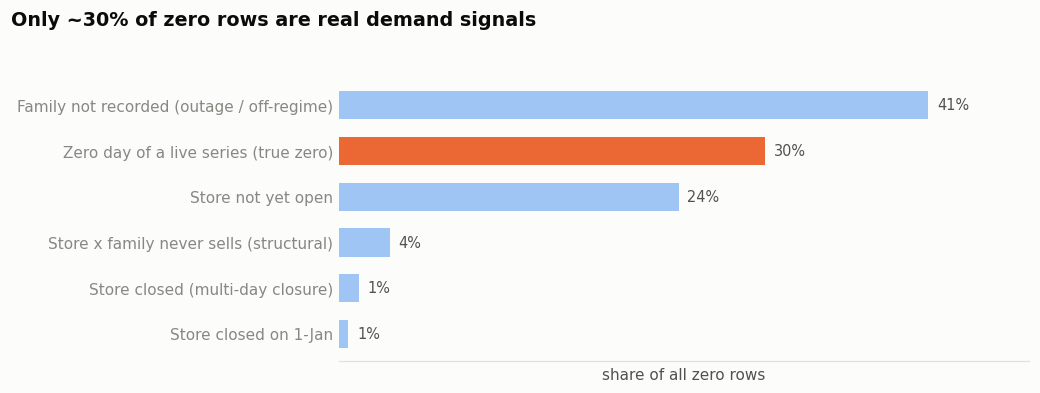

In [13]:
zz = z.iloc[:-1].sort_values("rows")
fig, ax = plt.subplots(figsize=(9.5, 3.6))
cols = [ORANGE if s.startswith("Zero day") else "#9ec5f4" for s in zz["cause of the zero"]]
ax.barh(zz["cause of the zero"], zz["% of zero rows"], color=cols, height=0.62)
for y, v in enumerate(zz["% of zero rows"]): ax.text(v + 0.6, y, f"{v:.0f}%", va="center", color=fv.INK2, fontsize=9.5)
ax.set_xlim(0, 48); ax.grid(False); ax.set_xticks([]); ax.tick_params(axis="y", length=0)
ftitle(fig, "Only ~30% of zero rows are real demand signals"); ax.set_xlabel("share of all zero rows")
finish(fig, "zero_causes")

**Business insight.** Of 939,130 zero rows only **30% are real demand signals** (a live series that sold nothing that day). The largest cause, at 41%, is *"family not recorded"* (13 families are missing for months at a time, in the same windows across the whole chain), 24% are stores that had not yet opened, and 3.6% are combinations that never sell at all.

In [14]:
# Store opening dates, extended closures, family recording gaps
open_df = pd.DataFrame({"store": P.stores, "first_sale": [P.dates[i].date() for i in P.open_idx]})
late = open_df[open_df.first_sale > pd.Timestamp("2013-01-05").date()].merge(st[["store_nbr", "city", "type"]], left_on="store", right_on="store_nbr").drop(columns="store_nbr")
print("Stores that opened after 2013 (their earlier zeros are 'not open', not 'no demand'):"); print(late.to_string(index=False))
ext = []
for j, s in enumerate(P.stores):
    x = P.closed_ext[:Tt, j]; g = (x != np.roll(x, 1)).cumsum()
    for _, seg in pd.Series(x).groupby(g):
        if seg.iloc[0] and len(seg) >= 3:
            ext.append((s, P.dates[seg.index[0]].date(), P.dates[seg.index[-1]].date(), len(seg)))
print("\nMulti-day closures of an open store (all 33 families = 0):")
print(pd.DataFrame(ext, columns=["store", "from", "to", "days"]).to_string(index=False))

Stores that opened after 2013 (their earlier zeros are 'not open', not 'no demand'):
 store first_sale          city type
    20 2015-02-13         Quito    B
    21 2015-07-24 Santo Domingo    B
    22 2015-10-09          Puyo    C
    29 2015-03-20     Guayaquil    E
    36 2013-05-09      Libertad    E
    42 2015-08-21        Cuenca    D
    52 2017-04-20         Manta    A
    53 2014-05-29         Manta    D

Multi-day closures of an open store (all 33 families = 0):
 store       from         to  days
    12 2015-03-30 2015-05-28    60
    14 2014-08-04 2014-09-10    38
    18 2016-08-15 2016-12-02   110
    24 2014-04-14 2014-07-23   101
    25 2016-08-22 2016-10-26    66
    30 2013-07-08 2013-07-30    23
    43 2016-11-14 2016-11-17     4


In [15]:
gaps = []
for j, f in enumerate(P.fams):
    x = P.outage_all[:Tt, j]
    if x.any():
        launch = P.dates[P.fam_launch[j]].date()
        g = (x != np.roll(x, 1)).cumsum(); segs = [(P.dates[s.index[0]].date(), P.dates[s.index[-1]].date(), len(s)) for _, s in pd.Series(x).groupby(g) if s.iloc[0]]
        after = [s for s in segs if s[0] > launch]
        gaps.append(dict(family=f, first_recorded_sale=launch, days_masked=int(x.sum()), gaps_after_launch=len(after),
                         days_in_gaps_after_launch=sum(s[2] for s in after), zero_run_outage=bool(P.outage[:Tt, j].any()), level_regime_family=bool(j in P.regime_fams)))
gaps_df = pd.DataFrame(gaps).sort_values("days_masked", ascending=False).reset_index(drop=True)
gaps_df

,family,first_recorded_sale,days_masked,gaps_after_launch,days_in_gaps_after_launch,zero_run_outage,level_regime_family
0,BOOKS,2016-10-08,1376,0,0,True,False
1,BABY CARE,2014-03-01,751,7,327,True,True
2,SCHOOL AND OFFICE SUPPLIES,2014-01-02,667,4,301,True,True
3,LADIESWEAR,2014-01-02,667,4,301,True,True
4,BEVERAGES,2013-01-01,666,4,301,False,True
5,CELEBRATION,2014-01-01,666,4,301,True,True
6,HOME AND KITCHEN II,2014-01-01,666,4,301,True,True
7,HOME AND KITCHEN I,2014-01-01,666,4,301,True,True
8,MAGAZINES,2014-01-01,666,4,301,True,True
9,HOME CARE,2014-01-01,666,4,301,True,True


**Stores.** Eight stores opened after 2013 (stores 20, 21, 22, 29, 36, 42, 52, 53); seven stores had multi-day closures, some very long (store 18: 110 days in 2016; store 24: 101 days in 2014; store 25: 66 days in 2016). All 33 families are zero in all these windows: the store was **closed**, so demand is unknown (missing), not zero. **Product families.** 13 families have long recording gaps; BOOKS only started to be recorded on 2016-10-08.

In [16]:
# Evidence for the "recording regimes": >=5 families vanish together in the same windows
x = pd.Series(P.off_regime[:Tt], index=P.dates[:Tt]); g = (x != x.shift()).cumsum()
wins = [(s.index[0].date(), s.index[-1].date(), len(s)) for _, s in x.groupby(g) if s.iloc[0]]
print("'off' windows (>=5 families with a zero-run at the same time):"); [print("  ", a, "->", b, f"({n} days)") for a, b, n in wins]
rr = pd.Series(P.regime_ratio, index=P.fams).dropna().sort_values()
print("\nmedian chain sales on 'off' days / 'on' days (2014-2015): families far below 1 change level with the regime")
print(rr.head(8).round(2).to_string()); print("...\n", rr.tail(3).round(2).to_string())

'off' windows (>=5 families with a zero-run at the same time):
   2013-01-01 -> 2013-12-31 (365 days)
   2014-02-01 -> 2014-02-28 (28 days)
   2014-04-01 -> 2014-06-30 (91 days)
   2014-08-01 -> 2014-08-31 (31 days)
   2015-01-01 -> 2015-05-31 (151 days)

median chain sales on 'off' days / 'on' days (2014-2015): families far below 1 change level with the regime
BABY CARE                    0.00
CELEBRATION                  0.00
SCHOOL AND OFFICE SUPPLIES   0.00
PLAYERS AND ELECTRONICS      0.00
PET SUPPLIES                 0.00
MAGAZINES                    0.00
LADIESWEAR                   0.00
HOME CARE                    0.00
...
 EGGS              0.97
SEAFOOD           0.98
HOME APPLIANCES   1.32


DAIRY    Oct-2013:   18,673   Jan-2014:   36,240   ratio 1.94
POULTRY  Oct-2013:   10,772   Jan-2014:   20,151   ratio 1.87


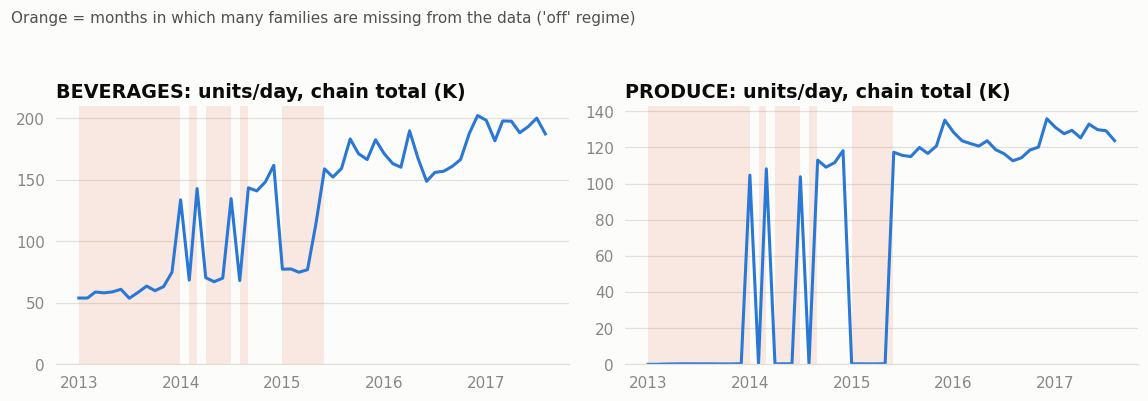

In [17]:
# a second, permanent kind of break: DAIRY and POULTRY roughly doubled in Nov-2013 (LFL stores, avg daily units)
lf_ = [i for i, s in enumerate(P.stores) if P.open_idx[i] <= 1]
for fam in ("DAIRY", "POULTRY"):
    j = P.fidx[fam]; s_ = pd.Series(np.nansum(P.A[:Tt][:, lf_, j], axis=1), index=P.dates[:Tt]); s_[P.dec25[:Tt]] = np.nan
    m_ = s_.resample("MS").mean()
    print(f"{fam:8s} Oct-2013: {m_['2013-10-01']:>8,.0f}   Jan-2014: {m_['2014-01-01']:>8,.0f}   ratio {m_['2014-01-01'] / m_['2013-10-01']:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, fam in zip(axs, ["BEVERAGES", "PRODUCE"]):
    j = P.fidx[fam]; s_ = pd.Series(np.nansum(P.A[:Tt, :, j], axis=1), index=P.dates[:Tt]); s_[P.dec25[:Tt]] = np.nan
    mo_ = s_.resample("MS").mean() / 1e3
    ax.plot(mo_.index, mo_.values, color=BLUE, lw=2)
    for a, b, n in wins: ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=ORANGE, alpha=.13, lw=0)
    ax.set_title(f"{fam}: units/day, chain total (K)"); ax.set_ylim(0, None)
fig.suptitle("Orange = months in which many families are missing from the data ('off' regime)", x=0.01, ha="left", fontsize=10, color=fv.INK2, y=1.0)
finish(fig, "recording_regimes")

**Discovery - "recording regimes".** The gaps are not random: in five windows (all of 2013, Feb 2014, Apr-Jun 2014, Aug 2014, Jan-May 2015) at least five families vanish *together*, and some families that stay recorded (BEVERAGES, PRODUCE, HOME AND KITCHEN...) change *level* with the regime (see chart). In addition, **DAIRY and POULTRY roughly doubled in Nov 2013** (x1.94 / x1.87) - a permanent break, most likely a change in product coverage of the record, not a demand change.
*Modeling decisions:* (1) mask all these days as missing (never zero) for both history features and targets; (2) treat 2013 - early 2015 as a different data regime and **train on origins from 2015-07-01** (an extended-window experiment from 2014-09-01 is defined in Phase 3); (3) compute store totals from the "stable" families only, so that a family dropping in or out of the record does not look like a store trend.

### 5b. Inactive (dormant) combinations - can a rule replace a model?
A store x family that has sold nothing for months will almost certainly sell nothing in the next 16 days. A transparent rule ("zero valid sales in the last N days => forecast 0") is cheaper, auditable and more accurate than a model that would output small positive numbers. We back-test the rule on every historical Tuesday origin: *precision* = share of flagged combinations that really sold nothing in the following 16 days.

In [18]:
# --- The activity rule: can we trust "zero for 90 days => zero for the next 16"?  Back-test on every Tuesday origin.
def dormant_backtest(window, min_valid, exempt=()):
    rows = []; C = P.C
    for t in range(120, Tt - 16):
        if P.dates[t].dayofweek != 1: continue
        past, fut = C[t - window + 1: t + 1], C[t + 1: t + 17]
        nv, ps = np.sum(~np.isnan(past), 0), np.nansum(past, 0)
        dorm = (ps == 0) & (nv >= min_valid)
        for e in exempt: dorm[:, P.fidx[e]] = False
        fv_, fn = np.nansum(fut, 0), np.sum(~np.isnan(fut), 0); ok = fn >= 8
        m = dorm & ok
        rows.append((dorm[ok].sum(), ok.sum(), (m & (fv_ == 0)).sum(), m.sum(), fv_[m & (fv_ > 0)]))
    flagged = sum(r[3] for r in rows); right = sum(r[2] for r in rows); tot = sum(r[1] for r in rows)
    wrong = np.concatenate([r[4] for r in rows])
    return dict(window_days=window, flagged=flagged, coverage=flagged / tot, precision=right / flagged,
                median_units_when_wrong=np.median(wrong), share_wrong_ge_50_units=(wrong >= 50).mean())
bt = pd.DataFrame([dormant_backtest(w, w // 2) for w in (30, 60, 90, 120)]).set_index("window_days")
bt.style.format({"coverage": "{:.1%}", "precision": "{:.1%}", "median_units_when_wrong": "{:.0f}", "share_wrong_ge_50_units": "{:.0%}", "flagged": "{:,.0f}"})

,flagged,coverage,precision,median_units_when_wrong,share_wrong_ge_50_units
window_days,,,,,
30,"13,386",4.3%,90.7%,5,3%
60,"11,368",3.6%,94.1%,6,4%
90,"10,013",3.2%,95.5%,6,6%
120,"9,041",2.9%,96.1%,6,6%


In [19]:
# where does the rule fail?  (90-day window)
C = P.C; rows = []
for t in range(120, Tt - 16):
    if P.dates[t].dayofweek != 1: continue
    past, fut = C[t - 89: t + 1], C[t + 1: t + 17]
    dorm = (np.nansum(past, 0) == 0) & (np.sum(~np.isnan(past), 0) >= 45)
    fv_, fn = np.nansum(fut, 0), np.sum(~np.isnan(fut), 0)
    for s, f in np.argwhere(dorm & (fn >= 8)): rows.append((P.fams[f], P.dates[t], fv_[s, f] > 0, P.dates[t].month))
bf = pd.DataFrame(rows, columns=["family", "origin", "woke_up", "month"])
by_f = bf.groupby("family").woke_up.agg(["size", "mean"]).rename(columns={"size": "flagged", "mean": "woke_up_rate"}).sort_values("woke_up_rate", ascending=False)
print(by_f.head(6).round(3).to_string())
aug = bf[bf.month.isin([7, 8, 9])].groupby("family").woke_up.agg(["size", "mean"]).sort_values("mean", ascending=False).head(3)
print("\nJul-Sep origins only (the season of the test window):"); print(aug.round(3).to_string())

                            flagged  woke_up_rate
family                                           
SEAFOOD                          53          0.30
BEAUTY                            7          0.29
PET SUPPLIES                     16          0.25
HOME APPLIANCES                 650          0.18
SCHOOL AND OFFICE SUPPLIES      847          0.11
BABY CARE                      3015          0.04

Jul-Sep origins only (the season of the test window):
                            size  mean
family                                
SEAFOOD                       51  0.31
SCHOOL AND OFFICE SUPPLIES   203  0.18
PET SUPPLIES                  11  0.09


In [20]:
bt2 = pd.DataFrame([dormant_backtest(90, 45, exempt=fv.SEASONAL_EXEMPT)]).set_index("window_days")
print("90-day rule with the seasonal exemption:"); bt2.style.format({"coverage": "{:.1%}", "precision": "{:.1%}", "median_units_when_wrong": "{:.0f}", "share_wrong_ge_50_units": "{:.0%}", "flagged": "{:,.0f}"})

90-day rule with the seasonal exemption:


,flagged,coverage,precision,median_units_when_wrong,share_wrong_ge_50_units
window_days,,,,,
90,"9,166",2.9%,96.1%,6,2%


**Findings.** A longer window is safer: precision rises from 90.7% (30 days) to 96.1% (120 days) while coverage stays at 3-4% of series. We use **90 days with >= 45 valid days** (precision 95.5%). The failures are not random: they concentrate in `SCHOOL AND OFFICE SUPPLIES` (847 flags, 11% woke up - **18% in Jul-Sep origins**, i.e. exactly the season of the test window, because of the back-to-school peak) and in a few tiny, erratic families (SEAFOOD, BEAUTY, PET SUPPLIES). Exempting school supplies lifts precision to 96.1% and cuts the share of wrong flags that cost >= 50 units to 2%.

In [21]:
# --- Activity status of all 1,782 store x family combinations at the forecast origin (2017-08-15) -------------
t_end = Tt - 1
past90 = P.C[t_end - 89: t_end + 1]
zr = np.nanmean(past90 == 0, axis=0); m90 = np.nanmean(past90, axis=0)
dorm = fv.dormant_flag(P, t_end)
last_sale = np.where(np.nan_to_num(P.C[: t_end + 1]) > 0, np.arange(t_end + 1)[:, None, None], -1).max(0)
status = np.where(dorm, "dormant", np.where(zr >= 0.5, "intermittent", "regular"))
act = pd.DataFrame({"store_nbr": np.repeat(P.stores, len(P.fams)), "family": np.tile(P.fams, len(P.stores)),
                    "status": status.reshape(-1), "zero_rate_90d": zr.reshape(-1), "mean_daily_sales_90d": m90.reshape(-1),
                    "days_since_last_sale": np.where(last_sale >= 0, t_end - last_sale, np.nan).reshape(-1),
                    "never_sold": never.reshape(-1)})
act.loc[act.never_sold, "status"] = "never sold"
print(act.status.value_counts().to_string())
print("\nshare of last-90-day sales volume by status:")
vol = act.assign(v=act.mean_daily_sales_90d.fillna(0)).groupby("status").v.sum(); print((vol / vol.sum()).map("{:.3%}".format).to_string())
print("\nfamilies holding most dormant / never-sold combos:"); print(act[act.status.isin(["dormant", "never sold"])].groupby("family").size().sort_values(ascending=False).head(8).to_string())
act.to_csv("store_family_activity_status.csv", index=False)

status
regular         1544
intermittent     158
never sold        53
dormant           27

share of last-90-day sales volume by status:
status
dormant          0.000%
intermittent     0.007%
never sold       0.000%
regular         99.993%

families holding most dormant / never-sold combos:
family
BOOKS              34
BABY CARE          21
LAWN AND GARDEN    14
LADIESWEAR         11


**Business insight.** At the real forecast origin (2017-08-15), 1,544 of the 1,782 combinations are regular sellers, 158 are intermittent, and **80 (4.5%) are inactive - 53 never sold, 27 dormant** (mostly BOOKS, BABY CARE, LAWN AND GARDEN, LADIESWEAR). Together they carry **less than 0.01% of volume**.
**Modeling decision - answering "should zero-demand combinations be modeled?":** dormant / never-sold combinations are **not modeled**: they are forecast as 0 by the `rule_zero` flag (with `SCHOOL AND OFFICE SUPPLIES` exempt). Intermittent-but-alive series **are** modeled - their zeros are information - and get `roll_zero_rate_*` and `days_since_last_sale` features. Store-closed days, not-yet-open days, outage days and 25-Dec are excluded from targets and treated as missing in history. The file `store_family_activity_status.csv` records the status of every combination at the forecast origin.

## 6. Sales trends by year, month, week and day of week
Raw totals are misleading here: 2013 -> 2016 total sales double mostly because stores opened and families started to be recorded. So growth is measured **like-for-like (LFL)**: only stores open since Jan-2013 with no long closure, and only families recorded continuously (39 stores x 19 families).

In [22]:
# --- 6. Trends ---------------------------------------------------------------------------------------------
# Like-for-like (LFL) panel: stores open since Jan-2013 and never closed for >3 days, families recorded all the way.
ever_closed = {s for s, *_ in ext}
lfl_stores = [i for i, s in enumerate(P.stores) if P.open_idx[i] <= 1 and s not in ever_closed]
lfl_fams = list(P.stable_fams)                                   # families recorded continuously after launch
print(f"LFL panel: {len(lfl_stores)} stores x {len(lfl_fams)} families (stable stores, continuously recorded families)")
lfl = np.nansum(P.A[:Tt][:, lfl_stores][:, :, lfl_fams], axis=(1, 2)); lfl = pd.Series(lfl, index=P.dates[:Tt]); lfl[P.dec25[:Tt]] = np.nan
tot_all = pd.Series(np.nansum(P.A[:Tt], axis=(1, 2)), index=P.dates[:Tt]); tot_all[P.dec25[:Tt]] = np.nan
yr = pd.DataFrame({"days": tot_all.groupby(tot_all.index.year).count(), "total_sales_M": tot_all.groupby(tot_all.index.year).sum() / 1e6,
                   "avg_daily_all_K": tot_all.groupby(tot_all.index.year).mean() / 1e3, "avg_daily_LFL_K": lfl.groupby(lfl.index.year).mean() / 1e3})
yr["LFL growth %"] = yr.avg_daily_LFL_K.pct_change() * 100
ytd = lfl[lfl.index.strftime("%m-%d") <= "08-15"].groupby(lambda d: d.year).mean() / 1e3
yr["LFL Jan-15 Aug avg daily K"] = ytd; yr["LFL YTD growth %"] = ytd.pct_change() * 100
yr

LFL panel: 39 stores x 19 families (stable stores, continuously recorded families)


,days,total_sales_M,avg_daily_all_K,avg_daily_LFL_K,LFL growth %,LFL Jan-15 Aug avg daily K,LFL YTD growth %
2013,364,140.42,385.77,290.82,NaN,274.68,NaN
2014,364,209.47,575.48,345.37,18.76,330.04,20.15
2015,364,240.88,661.76,372.41,7.83,362.81,9.93
2016,365,288.65,790.83,389.37,4.55,377.45,4.03
2017,227,194.22,855.58,405.12,4.04,405.12,7.33


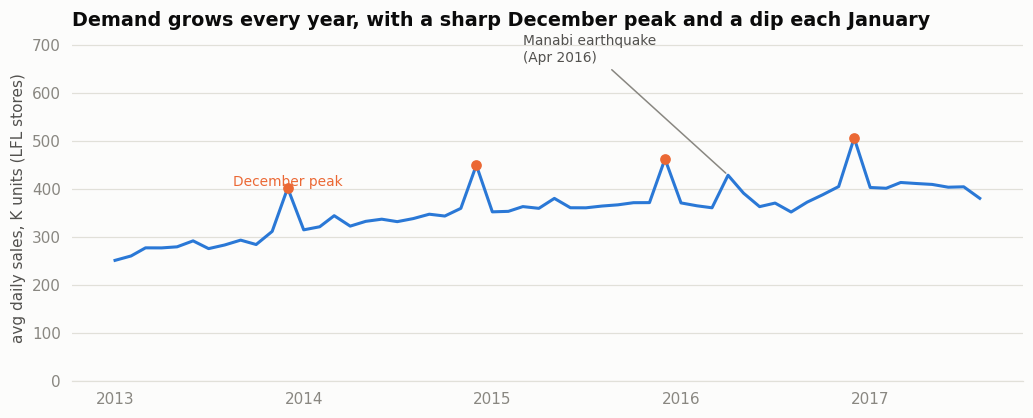

In [23]:
mon = lfl.resample("MS").mean() / 1e3
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.plot(mon.index, mon.values, color=BLUE, lw=2)
ax.set_ylim(0, 720); ax.set_ylabel("avg daily sales, K units (LFL stores)")
ax.annotate("Manabi earthquake\n(Apr 2016)", xy=(pd.Timestamp("2016-04-01"), mon["2016-04-01"]), xytext=(pd.Timestamp("2015-03-01"), 665),
            arrowprops=dict(arrowstyle="-", color=MUTED), color=fv.INK2, fontsize=9)
for y in range(2013, 2017):
    d = pd.Timestamp(f"{y}-12-01"); ax.plot(d, mon[d], "o", color=ORANGE, ms=6); 
ax.text(pd.Timestamp("2013-12-01"), mon[pd.Timestamp("2013-12-01")] + 4, "December peak", color=ORANGE, ha="center", fontsize=9)
ax.set_title("Demand grows every year, with a sharp December peak and a dip each January")
finish(fig, "trend_monthly")

**Business insight.** Underlying demand keeps growing but the growth is **decelerating**: +18.8% (2014), +7.8% (2015), +4.6% (2016); January-to-mid-August 2017 is +7.3% above the same period of 2016. Each year has a sharp December peak and a January dip. The April-2016 earthquake is visible as a one-off jump.

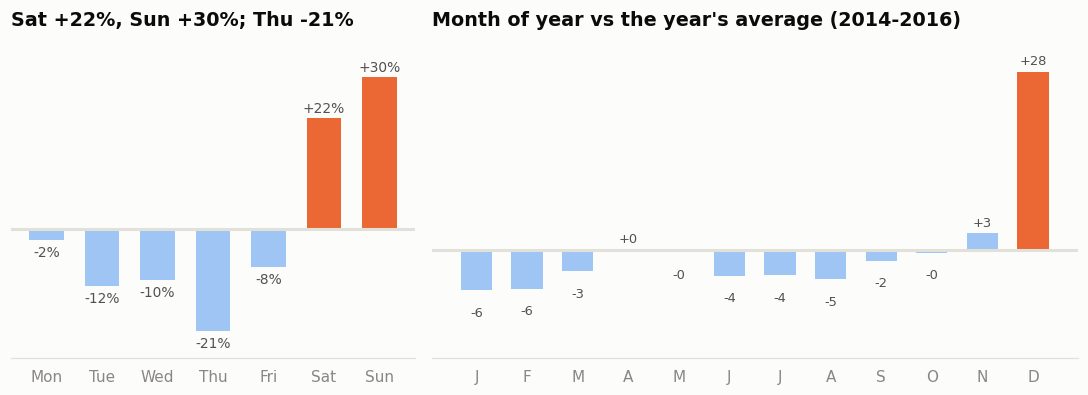

dow index: {0: 0.977, 1: 0.884, 2: 0.897, 3: 0.794, 4: 0.922, 5: 1.221, 6: 1.304}
month index: {1: 0.937, 2: 0.939, 3: 0.967, 4: 1.001, 5: 0.997, 6: 0.96, 7: 0.961, 8: 0.954, 9: 0.983, 10: 0.996, 11: 1.027, 12: 1.281}


In [24]:
# day-of-week and month-of-year indices (LFL, each year normalised by its own average -> growth removed)
l = lfl.dropna().to_frame("s"); l["year"] = l.index.year; l["dow"] = l.index.dayofweek; l["month"] = l.index.month
l["idx"] = l.s / l.groupby("year").s.transform("mean")
dow_idx = l.groupby("dow").idx.mean()
full_years = l[l.year.between(2014, 2016)]
month_idx = full_years.groupby("month").idx.mean()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.7), gridspec_kw={"width_ratios": [1, 1.6]})
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
axs[0].bar(names, (dow_idx - 1) * 100, color=[ORANGE if n in ("Sat", "Sun") else "#9ec5f4" for n in names], width=0.62)
for i, v in enumerate((dow_idx - 1) * 100): axs[0].text(i, v + (1.2 if v > 0 else -3.2), f"{v:+.0f}%", ha="center", fontsize=9, color=fv.INK2)
axs[0].set_title(f"Sat {(dow_idx[5]-1)*100:+.0f}%, Sun {(dow_idx[6]-1)*100:+.0f}%; Thu {(dow_idx[3]-1)*100:+.0f}%"); axs[0].set_yticks([]); axs[0].grid(False); axs[0].axhline(0, color=fv.GRID)
mn = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
axs[1].bar(range(1, 13), (month_idx - 1) * 100, color=[ORANGE if m == 12 else "#9ec5f4" for m in range(1, 13)], width=0.62)
axs[1].set_xticks(range(1, 13)); axs[1].set_xticklabels(mn); axs[1].set_yticks([]); axs[1].grid(False); axs[1].axhline(0, color=fv.GRID)
for m, v in ((month_idx - 1) * 100).items(): axs[1].text(m, v + (1.2 if v > 0 else -4), f"{v:+.0f}", ha="center", fontsize=8.5, color=fv.INK2)
axs[1].set_ylim(-17, 34); axs[0].set_ylim(-26, 39); axs[1].set_title("Month of year vs the year's average (2014-2016)")
finish(fig, "seasonality_dow_month")
print("dow index:", dow_idx.round(3).to_dict()); print("month index:", month_idx.round(3).to_dict())

**Business insight - the weekly and yearly rhythm.** **Sunday (+30%) and Saturday (+22%) are the strong days; Thursday is the weakest (-21%)**, with Tuesday/Wednesday also below average. December is +28% above the average month; January-February are ~6% below; mid-year months sit at 95-97%. A 16-day forecast always spans two weekends, so the weekday pattern is the single biggest structure a model must capture.
*Modeling decisions:* weekday, month, day-of-month and week-of-year features; growth is captured with recent-level features (rolling means) rather than a global time trend; because the level shifts each year, models are validated *forward in time*, never with random splits.

## 7. Store performance - by store, city, state, type and cluster
Which stores carry the volume, and do the store attributes (type, cluster, city) explain the differences?

In [25]:
# --- 7. Stores ------------------------------------------------------------------------------------------------
raw_store = pd.Series(np.nansum(P.A[:Tt], axis=(0, 2)), index=P.stores)
rec = P.tot_clean[Tt - 240: Tt]                                         # last 240 days, closures/pre-open excluded
sp = pd.DataFrame({"store_nbr": P.stores, "total_sales_M": raw_store.values / 1e6,
                   "avg_daily_240d": np.nanmean(rec, axis=0), "open_since": [P.dates[i].date() for i in P.open_idx]}).merge(st, on="store_nbr")
sp["share_%"] = sp.total_sales_M / sp.total_sales_M.sum() * 100
def grp(col):
    g = sp.groupby(col).agg(stores=("store_nbr", "size"), total_M=("total_sales_M", "sum"), avg_daily_per_store=("avg_daily_240d", "mean"),
                            median_daily=("avg_daily_240d", "median"), min_daily=("avg_daily_240d", "min"), max_daily=("avg_daily_240d", "max"))
    g["share_%"] = g.total_M / g.total_M.sum() * 100
    return g.sort_values("total_M", ascending=False)
print("BY TYPE"); print(grp("type").round(1).to_string())
print("\nBY STATE"); print(grp("state").head(6).round(1).to_string())
print("\nBY CITY"); print(grp("city").head(8).round(1).to_string())
print("\nBY CLUSTER (top 6 by sales)"); print(grp("cluster").head(6).round(1).to_string())

BY TYPE
      stores  total_M  avg_daily_per_store  median_daily  min_daily  max_daily  share_%
type                                                                                   
A          9   353.00            33,005.00     32,579.90  22,181.60  46,826.50    32.90
D         18   351.10            15,486.10     13,839.00   5,452.40  38,978.90    32.70
C         15   164.40             8,525.70      8,010.70   5,060.80  15,659.30    15.30
B          8   145.30            15,391.70     14,943.80  11,388.70  20,708.90    13.50
E          4    59.80            13,777.30     13,677.90  12,444.20  15,309.20     5.60

BY STATE
                                stores  total_M  avg_daily_per_store  median_daily  min_daily  max_daily  share_%
state                                                                                                            
Pichincha                           19   585.10            24,248.10     20,708.90   6,585.80  46,826.50    54.50
Guayas                  

top-5 stores:
 store_nbr  city type  cluster  avg_daily_240d  share_%
        44 Quito    A        5       46,826.50     5.80
        45 Quito    A       11       43,332.80     5.10
        47 Quito    A       14       40,522.80     4.70
         3 Quito    D        8       38,978.90     4.70
        49 Quito    A       11       37,521.80     4.00
bottom-5 stores (open >1 year):
 store_nbr      city type  cluster  avg_daily_240d  share_%
        32 Guayaquil    C        3        5,060.80     0.60
        26 Guayaquil    D       10        5,452.40     0.70
        35    Playas    C        3        5,766.50     0.70
        30 Guayaquil    C        3        5,836.50     0.70
        10     Quito    C       15        6,585.80     0.90

top-10 stores = 38% of all sales; ratio best/median store (avg daily) = 3.4x


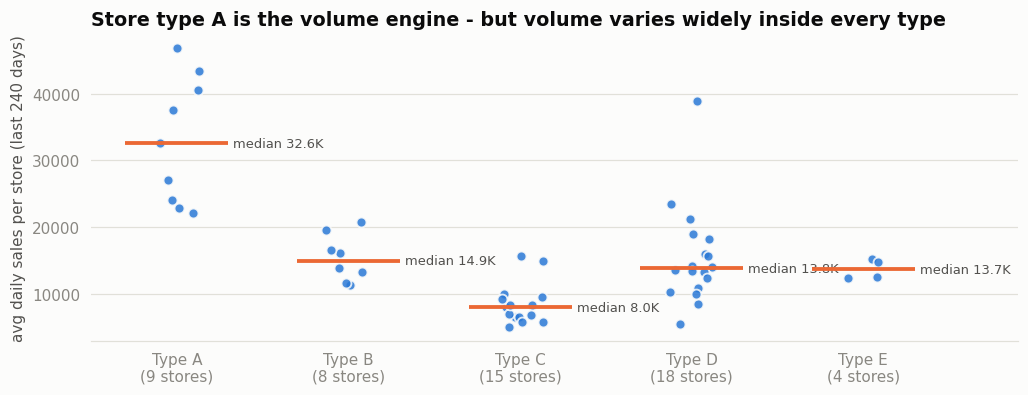

In [26]:
print("top-5 stores:"); print(sp.nlargest(5, "avg_daily_240d")[["store_nbr", "city", "type", "cluster", "avg_daily_240d", "share_%"]].round(1).to_string(index=False))
print("bottom-5 stores (open >1 year):"); print(sp[sp.open_since < pd.Timestamp("2016-08-01").date()].nsmallest(5, "avg_daily_240d")[["store_nbr", "city", "type", "cluster", "avg_daily_240d", "share_%"]].round(1).to_string(index=False))
q = sp.sort_values("avg_daily_240d", ascending=False)
top10_share = q.head(10)["total_sales_M"].sum() / q.total_sales_M.sum()
print(f"\ntop-10 stores = {top10_share:.0%} of all sales; ratio best/median store (avg daily) = {q.avg_daily_240d.max() / q.avg_daily_240d.median():.1f}x")
fig, ax = plt.subplots(figsize=(9.5, 3.7))
order = list("ABCDE"); rng = np.random.default_rng(1)
for i, tp in enumerate(order):
    v = sp[sp.type == tp].avg_daily_240d.values
    ax.scatter(np.full(len(v), i) + rng.uniform(-.14, .14, len(v)), v, s=42, color=BLUE, alpha=.85, edgecolor=fv.SURFACE, lw=1.2, zorder=3)
    ax.hlines(np.median(v), i - .3, i + .3, color=ORANGE, lw=2.5, zorder=4)
    ax.text(i + .33, np.median(v), f"median {np.median(v) / 1e3:.1f}K", va="center", fontsize=8.5, color=fv.INK2)
ax.set_xticks(range(5)); ax.set_xticklabels([f"Type {t}\n({(sp.type == t).sum()} stores)" for t in order]); ax.set_xlim(-.5, 4.9)
ax.set_ylabel("avg daily sales per store (last 240 days)")
ax.set_title("Store type A is the volume engine - but volume varies widely inside every type")
finish(fig, "store_type")

**Business insight.** Sales are concentrated: **the top 10 stores generate 38% of all sales, and the best store sells 3.4x the median store per day** (store 44, Quito: ~46,800 units/day; the smallest, store 32 in Guayaquil: ~5,100). Geographically, **Pichincha (Quito) is 54.5% of sales** and Guayas (Guayaquil) 15.4%. By type, A stores (9 stores) deliver 32.9% of sales at ~33,000 units/day each; type D (18 stores) also 32.7% but with a very wide range (5,500-39,000 units/day per store), i.e. **store type alone does not describe size** - clusters and, above all, the store identity are needed.
*Modeling decisions:* keep `store_nbr` as a strong identifier; type / cluster / city / state as secondary attributes; recent store-level totals as features (they carry the store's current level and trend).

## 8. Product-family performance - fast movers, slow movers and low-volume lines

In [27]:
# --- 8. Product families ---------------------------------------------------------------------------------------
last365 = slice(Tt - 365, Tt)
fs = pd.DataFrame({"family": P.fams, "total_units_M": np.nansum(P.A[:Tt], axis=(0, 1)) / 1e6,
                   "units_last365_M": np.nansum(P.A[last365], axis=(0, 1)) / 1e6,
                   "avg_daily_chain_last365": np.nanmean(np.nansum(P.C[last365], axis=1), axis=0),
                   "stores_selling_last90d": (np.nansum(P.C[Tt - 90:Tt], axis=0) > 0).sum(0)})
zr_f = np.nanmean(P.C[last365] == 0, axis=(0, 1)); fs["zero_rate_valid_last365"] = zr_f
fs = fs.sort_values("units_last365_M", ascending=False).reset_index(drop=True)
fs["share_%"] = fs.units_last365_M / fs.units_last365_M.sum() * 100; fs["cum_%"] = fs["share_%"].cumsum()
fs["class"] = np.where(fs["cum_%"] - fs["share_%"] < 80, "A fast-moving", np.where(fs["cum_%"] - fs["share_%"] < 95, "B slow-moving", "C low-volume"))
fs.round(2)

,family,total_units_M,units_last365_M,avg_daily_chain_last365,stores_selling_last90d,zero_rate_valid_last365,share_%,cum_%,class
0,GROCERY I,343.46,90.81,"248,782.78",54,0.00,29.65,29.65,A fast-moving
1,BEVERAGES,216.95,68.11,"186,591.92",54,0.00,22.23,51.88,A fast-moving
2,PRODUCE,122.70,45.88,"125,704.34",54,0.00,14.98,66.86,A fast-moving
3,CLEANING,97.52,24.19,"66,276.83",54,0.00,7.90,74.76,A fast-moving
4,DAIRY,64.49,18.02,"49,374.67",54,0.00,5.88,80.64,A fast-moving
5,BREAD/BAKERY,42.13,10.72,"29,359.57",54,0.00,3.50,84.14,B slow-moving
6,POULTRY,31.88,7.67,"21,016.81",54,0.00,2.50,86.64,B slow-moving
7,MEATS,31.09,7.25,"19,872.77",54,0.00,2.37,89.01,B slow-moving
8,PERSONAL CARE,24.59,6.30,"17,262.03",54,0.00,2.06,91.07,B slow-moving
9,DELI,24.11,6.11,"16,750.49",54,0.00,2.00,93.06,B slow-moving


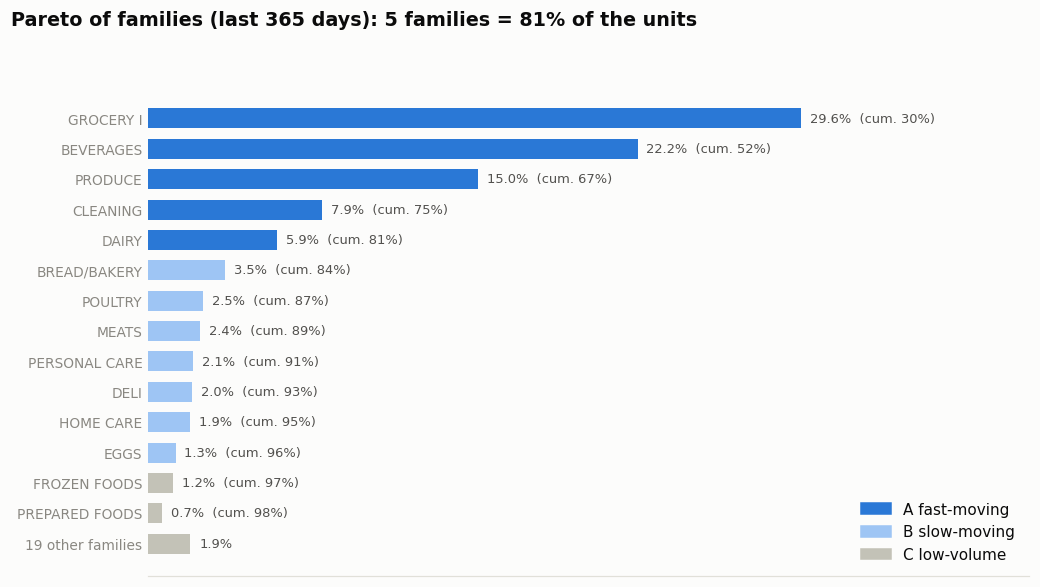

In [28]:
top = fs.head(14).copy()
oth = fs.iloc[14:]
top.loc[len(top)] = [f"{len(oth)} other families", oth.total_units_M.sum(), oth.units_last365_M.sum(), np.nan, np.nan, np.nan, oth["share_%"].sum(), 100.0, "C low-volume"]
g = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.4))
colmap = {"A fast-moving": BLUE, "B slow-moving": "#9ec5f4", "C low-volume": "#c3c2b7"}
ax.barh(g.family, g["share_%"], color=[colmap[c] for c in g["class"]], height=0.66)
for y, (v, c, k) in enumerate(zip(g["share_%"], g["cum_%"], g.family)): ax.text(v + 0.4, y, f"{v:.1f}%" + ("" if k.endswith("families") else f"  (cum. {c:.0f}%)"), va="center", fontsize=8.5, color=fv.INK2)
ax.grid(False); ax.set_xticks([]); ax.tick_params(axis="y", labelsize=9, length=0); ax.set_xlim(0, 40)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colmap.items()], loc="lower right")
ftitle(fig, f"Pareto of families (last 365 days): {int((fs['class'] == 'A fast-moving').sum())} families = {fs.head(int((fs['class'] == 'A fast-moving').sum()))['share_%'].sum():.0f}% of the units")
finish(fig, "family_pareto")

**Business insight.** The chain is a **Pareto business**: five families (GROCERY I, BEVERAGES, PRODUCE, CLEANING, DAIRY) make up **80.6%** of units in the last 365 days; seven more (up to POULTRY, MEATS, PERSONAL CARE, DELI, HOME CARE, EGGS, BREAD/BAKERY) bring the total to 96%; the remaining **21 low-volume families share only 3.8%**. The fast movers sell in every store every day (zero rate 0%); several low-volume lines (BABY CARE, BOOKS, HOME APPLIANCES, SCHOOL AND OFFICE SUPPLIES, HARDWARE) are zero on 39-83% of days.

In [29]:
# growth by family (LFL stores only, Jan-15 Aug 2017 vs same period 2016)
lf_s = lfl_stores
def period_sum(a, b): 
    i0, i1 = P.date_idx(a), P.date_idx(b) + 1
    return np.nansum(P.C[i0:i1][:, lf_s], axis=(0, 1))
gr = pd.DataFrame({"family": P.fams, "y2016": period_sum("2016-01-01", "2016-08-15"), "y2017": period_sum("2017-01-01", "2017-08-15")})
gr = gr[gr.y2016 > 50000]; gr["yoy_%"] = (gr.y2017 / gr.y2016 - 1) * 100
print("YoY growth Jan-15 Aug (LFL stores; only families with >50k units in 2016):"); print(pd.concat([gr.nlargest(5, "yoy_%"), gr.nsmallest(5, "yoy_%")])[["family", "y2016", "y2017", "yoy_%"]].round(1).to_string(index=False))
print("chain LFL total YoY %:", round((gr.y2017.sum() / gr.y2016.sum() - 1) * 100, 1))

YoY growth Jan-15 Aug (LFL stores; only families with >50k units in 2016):
                 family        y2016        y2017  yoy_%
        LAWN AND GARDEN    50,373.00   155,177.00 208.10
           PET SUPPLIES    66,312.00    89,191.00  34.50
             GROCERY II   211,427.00   268,170.00  26.80
PLAYERS AND ELECTRONICS    94,084.00   116,954.00  24.30
     HOME AND KITCHEN I   268,562.00   323,235.00  20.40
         PREPARED FOODS 1,078,185.00   982,714.20  -8.90
                SEAFOOD   262,382.60   242,431.30  -7.60
            CELEBRATION   142,086.00   135,052.00  -5.00
           FROZEN FOODS 1,340,674.60 1,294,601.60  -3.40
                POULTRY 4,038,400.80 4,079,083.90   1.00
chain LFL total YoY %: 8.0


**Growth by family (LFL stores, Jan-15 Aug 2017 vs 2016):** the chain grows 8.0%, but unevenly - PET SUPPLIES +34.5%, GROCERY II +26.8%, PLAYERS AND ELECTRONICS +24.3%, HOME AND KITCHEN I +20.4% (LAWN AND GARDEN's +208% comes from a tiny base); PREPARED FOODS (-8.9%), SEAFOOD (-7.6%), CELEBRATION (-5.0%) and FROZEN FOODS (-3.4%) are shrinking.
*Modeling decisions:* one **global** model with `family_id` as a feature (the 21 small families are too sparse to model separately) but *report error by family class*; use recent (28/91-day) levels rather than all-history means so that families in transition are tracked; expect the low-volume families to be the hardest and the fast movers to drive the business value.

## 9. Promotion effectiveness
`onpromotion` is the number of items of a family on promotion in a store on a day. It is the only *future-known* commercial driver in `test.csv`, so its usefulness matters. Two questions: is the promo distribution in the test window different from training, and do promotions actually lift sales?

In [30]:
# --- 9. Promotions -------------------------------------------------------------------------------------------------
# (a) coverage over time: is the train/test "shift" really a train-vs-test problem?

promotable = np.nansum(P.P[P.date_idx("2017-01-01"):Tt] > 0, axis=(0, 1)) > 0            # families ever promoted in 2017
def cover(a, b, mask=promotable):
    x = P.P[P.date_idx(a):P.date_idx(b) + 1][:, :, mask]; return np.nanmean(x > 0)
rows = [(str(y), cover(f"{y}-01-01", f"{y}-12-31")) for y in range(2013, 2018)]
rows += [("2017 Jan-Aug 15 (train)", cover("2017-01-01", "2017-08-15")), ("TEST 16-31 Aug 2017", cover("2017-08-16", "2017-08-31"))]
pc = pd.DataFrame(rows, columns=["period", "share of store-family-days on promotion"]).set_index("period")
print(f"families promoted at least once in 2017: {int(promotable.sum())} of {len(P.fams)}"); pc.style.format("{:.1%}")

families promoted at least once in 2017: 32 of 33


,share of store-family-days on promotion
period,
2013,0.0%
2014,10.3%
2015,21.5%
2016,36.0%
2017,46.6%
2017 Jan-Aug 15 (train),46.7%
TEST 16-31 Aug 2017,45.5%


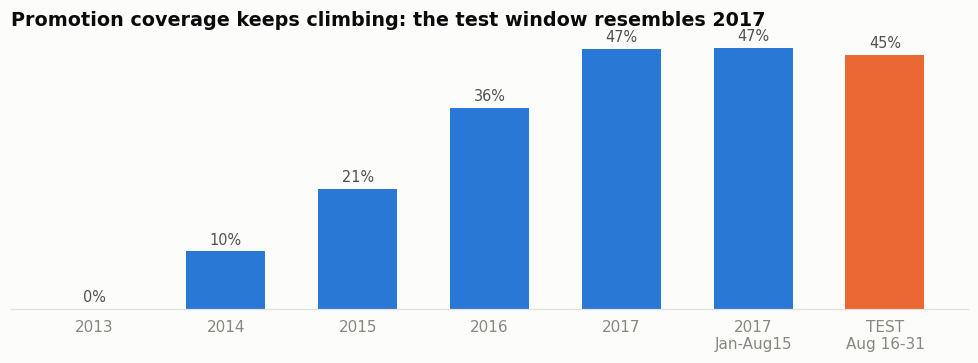

In [31]:
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = list(pc.index[:5]) + ["2017\nJan-Aug15", "TEST\nAug 16-31"]
ax.bar(xs, pc.iloc[:, 0] * 100, color=[BLUE] * 6 + [ORANGE], width=0.6)
for i, v in enumerate(pc.iloc[:, 0] * 100): ax.text(i, v + 1.2, f"{v:.0f}%", ha="center", fontsize=9.5, color=fv.INK2)
ax.set_yticks([]); ax.grid(False); ax.set_title("Promotion coverage keeps climbing: the test window resembles 2017")
finish(fig, "promo_coverage")

**Premise check - is there a train/test "shift"?** Promotion coverage grew steadily: 0% (2013), 10% (2014), 22% (2015), 36% (2016), 47% (2017). The test window sits at 45.5%, essentially where 2017 already is (46.7%). The "shift" between old training data and the test window is therefore a **time trend, not a train-vs-test problem** - it is solved by training on recent data, not by removing the feature.

In [32]:
# (b) uplift: promoted vs non-promoted days of the SAME store x family, relative to its own local level (centred 15-day mean)
pfC = fv.Prefix(P.C)
i0, i1 = P.date_idx("2016-01-01"), Tt
idx = np.arange(i0, i1); lo, hi = np.clip(idx - 7, 0, None), np.clip(idx + 8, None, Tt)
n_ = pfC.n[hi] - pfC.n[lo]; cm = np.where(n_ >= 8, (pfC.s[hi] - pfC.s[lo]) / np.maximum(n_, 1), np.nan)
Cw, Pw = P.C[i0:i1], P.P[i0:i1]
rel = np.where((cm > 0) & ~np.isnan(Cw), Cw / cm, np.nan)
dw = P.dates[i0:i1].dayofweek.values
for w in range(7):                                                            # remove each series' own weekday pattern
    rel[dw == w] = rel[dw == w] / np.nanmean(rel[dw == w], axis=0)
pro = (Pw > 0)
# three ways to answer "do promotions work?" -- the answer changes as confounders are removed
mask_ok = ~np.isnan(Cw) & ~np.isnan(Pw) & (np.nanmean(Cw, axis=0) >= 5)[None]
naive = np.nanmean(np.where(mask_ok & pro, Cw, np.nan)) / np.nanmean(np.where(mask_ok & ~pro, Cw, np.nan)) - 1
rel_nodow = np.where((cm > 0) & ~np.isnan(Cw), Cw / cm, np.nan)
def _series_uplift(r):
    a = np.where(pro, r, np.nan); b = np.where(~pro, r, np.nan)
    na, nb = np.sum(~np.isnan(a), 0), np.sum(~np.isnan(b), 0); good = (na >= 20) & (nb >= 20) & (np.nanmean(Cw, 0) >= 5)
    return np.where(good, np.nanmean(a, 0) / np.nanmean(b, 0) - 1, np.nan)
u_local = np.nanmedian(_series_uplift(rel_nodow)); 
def _mean(x, m): 
    v = np.where(m & ~np.isnan(x), x, np.nan); return np.nanmean(v, axis=0), np.sum(~np.isnan(v), axis=0)
m_p, n_p = _mean(rel, pro); m_n, n_n = _mean(rel, ~pro)
level = np.nanmean(Cw, axis=0)
ok = (n_p >= 20) & (n_n >= 20) & (level >= 5)
upl = np.where(ok, m_p / m_n - 1, np.nan)                                   # [S,F]
up_f = pd.DataFrame({"family": P.fams, "series_used": ok.sum(0), "median_uplift_%": np.nanmedian(upl, axis=0) * 100,
                     "share_series_positive_%": np.nanmean(upl > 0, axis=0) * 100, "avg_daily_chain": fs.set_index("family").loc[P.fams, "avg_daily_chain_last365"].values})
up_f = up_f[up_f.series_used >= 15].sort_values("avg_daily_chain", ascending=False)
overall = np.nanmedian(upl) * 100
print(f"series with enough promo & non-promo days: {int(ok.sum())}")
print(f"(1) naive: mean sales on promoted rows / non-promoted rows - 1 ...................... {naive * 100:+7.1f}%   (mixes big and small products)")
print(f"(2) same store x family, vs its own local level (centred 15-day mean) ............... {u_local * 100:+7.1f}%   (median over series)")
print(f"(3) ... and also removing the series' own weekday pattern ........................... {overall:+7.1f}%   (median over series)")
up_f.head(14).round(1).to_string(index=False)

series with enough promo & non-promo days: 1090
(1) naive: mean sales on promoted rows / non-promoted rows - 1 ......................  +617.1%   (mixes big and small products)
(2) same store x family, vs its own local level (centred 15-day mean) ...............    +6.8%   (median over series)
(3) ... and also removing the series' own weekday pattern ...........................    +2.3%   (median over series)


'          family  series_used  median_uplift_%  share_series_positive_%  avg_daily_chain\n       BEVERAGES           17             2.30                    24.10       186,591.90\n         PRODUCE           53             0.60                    74.10       125,704.30\n        CLEANING           42             2.50                    63.00        66,276.80\n           DAIRY           53            -0.20                    44.40        49,374.70\n    BREAD/BAKERY           54             0.20                    59.30        29,359.60\n         POULTRY           54             0.90                    81.50        21,016.80\n           MEATS           54             1.50                    87.00        19,872.80\n   PERSONAL CARE           52             2.30                    75.90        17,262.00\n            DELI           53             0.10                    50.00        16,750.50\n       HOME CARE           53             1.40                    85.20        16,213.50\n         

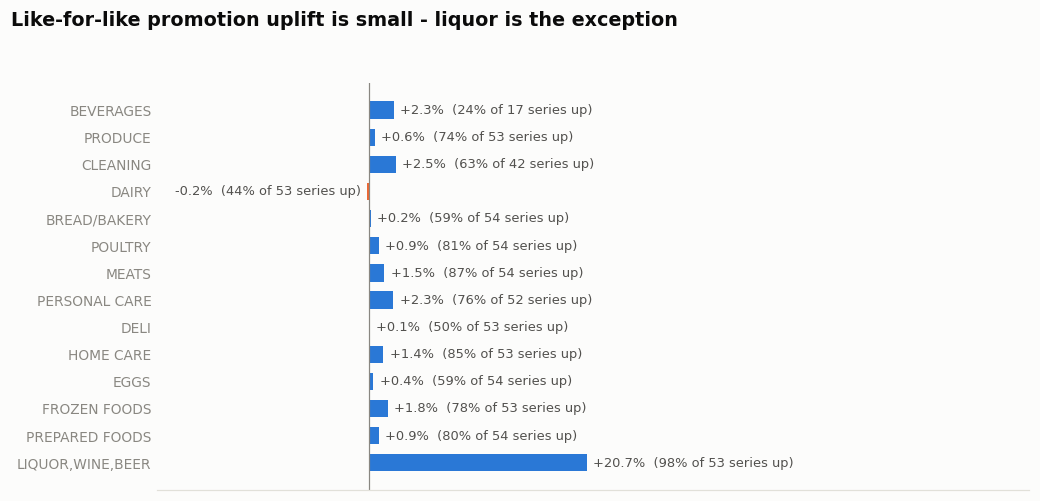

In [33]:
g = up_f.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.barh(g.family, g["median_uplift_%"], color=[BLUE if v >= 0 else ORANGE for v in g["median_uplift_%"]], height=0.64)
for y, (v, s_, n_s) in enumerate(zip(g["median_uplift_%"], g["share_series_positive_%"], g.series_used)): ax.text(v + (0.6 if v >= 0 else -0.6), y, f"{v:+.1f}%  ({s_:.0f}% of {n_s} series up)", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=fv.INK2)
ax.axvline(0, color=fv.MUTED, lw=0.8); ax.grid(False); ax.set_xticks([]); ax.tick_params(axis="y", length=0, labelsize=9)
ax.set_xlim(min(-8, g["median_uplift_%"].min() - 20), g["median_uplift_%"].max() + 42)
ftitle(fig, "Like-for-like promotion uplift is small - liquor is the exception")
finish(fig, "promo_uplift")

In [34]:
# (c) dose-response for the five fast-moving families: promo-count bucket vs relative sales
fast = [P.fidx[f] for f in fs.head(5).family]
bins = [-1, 0, 2, 5, 10, 20, 10 ** 6]; labs = ["0", "1-2", "3-5", "6-10", "11-20", "21+"]
rows = []
for lo_, hi_, lab in zip(bins[:-1], bins[1:], labs):
    m = (Pw[:, :, fast] > lo_) & (Pw[:, :, fast] <= hi_)
    r = rel[:, :, fast][m]; r = r[~np.isnan(r)]
    rows.append((lab, len(r), np.mean(r)))
dose = pd.DataFrame(rows, columns=["items on promotion", "store-days", "sales vs local level"]); dose["vs no promo %"] = (dose["sales vs local level"] / dose["sales vs local level"].iloc[0] - 1) * 100
dose.round(3)

,items on promotion,store-days,sales vs local level,vs no promo %
0,0,13358,0.99,0.00
1,1-2,14435,0.99,0.04
2,3-5,13208,0.99,0.20
3,6-10,16101,0.99,0.14
4,11-20,27173,1.00,0.40
5,21+,71765,1.01,1.44


**Do promotions work? It depends on how carefully you ask.** Promoted rows sell **+617%** more than non-promoted rows - but that only reflects that big products get promoted more. Comparing each series with *its own local level* the uplift is +6.8%, and after also removing the weekday pattern **+2.3%** (median over 1,090 series). By family the lift is small everywhere (-0.2% to +2.5% for the staples) with one exception: **LIQUOR, WINE, BEER +20.7%** (positive in 98% of stores). The dose-response for the five fast movers is monotonic but weak: 21+ items on promotion give about +1.4% vs no promotion.
**Business insight.** In this data, promotions are mostly a *weak* short-term demand lever except for alcohol; their value in a model is as a modest correction (and a proxy for policy/time), not a main driver. Inventory planners should not expect a 16-day forecast to jump because of a promotion count.
*Modeling decisions:* include `onpromotion`, `promo_flag` and **relative** promo features (promo vs the series' own 28-day norm) to cope with drift; no manual uplift rule; allow the model to learn family-specific promo effects (LIQUOR) through `family_id` interactions.

## 10. Holiday and event impact
Effect = sales on the day divided by the median of the same weekday +-3 weeks in the *same store* (so weekday and level effects are removed).

In [35]:
# --- 10. Holidays & events --------------------------------------------------------------------------------------------
def shifted(x, k):
    out = np.full_like(x, np.nan)
    if k > 0: out[k:] = x[:-k]
    else: out[:k] = x[-k:]
    return out
def dow_baseline(x):
    """mean of the same weekday +-1,2,3 weeks (needs >=3 valid neighbours)"""
    st_ = np.stack([shifted(x, k) for k in (7, 14, 21, -7, -14, -21)]); n = np.sum(~np.isnan(st_), 0)
    return np.where(n >= 3, np.nanmean(st_, 0), np.nan)
totc = P.tot_stable[:Tt]
rel_s = totc / dow_baseline(totc)
cats = {
    "National holiday": H["hol_national"][:Tt] == 1, "Regional holiday": H["hol_regional"][:Tt] == 1, "Local holiday (store's city)": H["hol_local"][:Tt] == 1,
    "Bridge day": H["bridge"][:Tt] == 1, "Additional day (Christmas run-up etc.)": H["additional"][:Tt] == 1, "Make-up Work Day (Sat)": H["work_day"][:Tt] == 1,
    "Day before a holiday": H["days_to_hol"][:Tt] == 1, "Day after a holiday": H["days_since_hol"][:Tt] == 1,
    "Mother's Day": H["event"][:Tt] == 1, "Black Friday": H["event"][:Tt] == 2, "Cyber Monday": H["event"][:Tt] == 3,
    "World Cup match days (2014)": H["event"][:Tt] == 4, "Earthquake +0..+30 days (Apr-May 2016)": H["event"][:Tt] == 5}
dec24 = np.array([(d.month == 12 and d.day == 24) for d in P.dates[:Tt]])[:, None] & np.ones((1, len(P.stores)), bool)
dec31 = np.array([(d.month == 12 and d.day == 31) for d in P.dates[:Tt]])[:, None] & np.ones((1, len(P.stores)), bool)
cats["24 Dec (Christmas Eve)"] = dec24; cats["31 Dec (New Year's Eve)"] = dec31
rows = []
for k, m in cats.items():
    v = rel_s[m]; v = v[~np.isnan(v)]
    rows.append((k, len(v), np.median(v) - 1, np.mean(v) - 1, np.mean(v > 1)))
hi_ = pd.DataFrame(rows, columns=["day type", "store-days", "median_effect", "mean_effect", "share_days_above_baseline"]).set_index("day type")
hi_.style.format({"median_effect": "{:+.1%}", "mean_effect": "{:+.1%}", "share_days_above_baseline": "{:.0%}", "store-days": "{:,.0f}"})

,store-days,median_effect,mean_effect,share_days_above_baseline
day type,,,,
National holiday,"2,149",+6.6%,+14.3%,59%
Regional holiday,28,+24.5%,+19.6%,71%
Local holiday (store's city),233,-1.6%,+0.1%,46%
Bridge day,148,+23.6%,+27.4%,84%
Additional day (Christmas run-up etc.),"1,562",+21.8%,+29.9%,80%
Make-up Work Day (Sat),240,-1.5%,+1.8%,48%
Day before a holiday,"2,241",-1.9%,+4.5%,46%
Day after a holiday,"2,339",+1.9%,+8.0%,53%
Mother's Day,249,-23.5%,-23.4%,2%


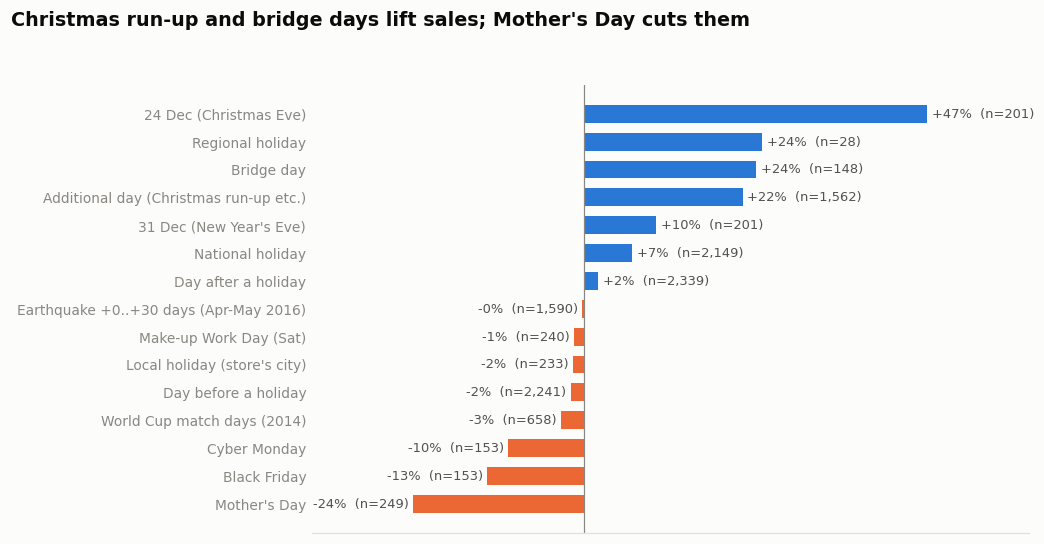

In [36]:
h2 = hi_.sort_values("median_effect")
fig, ax = plt.subplots(figsize=(9.5, 5.0))
ax.barh(h2.index, h2.median_effect * 100, color=[BLUE if v >= 0 else ORANGE for v in h2.median_effect], height=0.64)
for y, (v, n) in enumerate(zip(h2.median_effect * 100, h2["store-days"])): ax.text(v + (0.6 if v >= 0 else -0.6), y, f"{v:+.0f}%  (n={n:,.0f})", va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=fv.INK2)
ax.axvline(0, color=fv.MUTED, lw=0.8); ax.grid(False); ax.set_xticks([]); ax.tick_params(axis="y", length=0, labelsize=9)
ax.set_xlim(h2.median_effect.min() * 100 - 14, h2.median_effect.max() * 100 + 14)
ftitle(fig, "Christmas run-up and bridge days lift sales; Mother's Day cuts them")
finish(fig, "holiday_effect")

**Business insight.** Not all holidays are equal, and the file's single "Holiday" label hides that. **Christmas Eve (24 Dec) is +47%**, *Additional* days (the Christmas run-up) +22%, *Bridge* days +24%, and national holidays +6.6% at the median (+14% on average). Local holidays in a store's own city are *not* a sales day (-1.6% median) - shoppers travel or stay home. Events have negative effects on the day itself: **Mother's Day -23.5%, Black Friday -13.4%, Cyber Monday -10.5%**, and World Cup match days -3%.

In [37]:
# not all national holidays are equal: effect by holiday name (store-day index vs same weekday +-3 weeks, national days only)
nh = raw["hol"][(raw["hol"].locale == "National") & raw["hol"].type.isin(["Holiday", "Transfer"]) & ~raw["hol"].transferred]
nh = nh.assign(name=nh.description.str.replace("Traslado ", "", regex=False))
rows = []
for r in nh.itertuples():
    t = (r.date - P.dates[0]).days
    if 0 <= t < Tt:
        v = rel_s[t][~np.isnan(rel_s[t])]
        if len(v): rows.append((r.name, r.date.year, np.median(v) - 1, r.date.day_name()))
hn = pd.DataFrame(rows, columns=["holiday", "year", "effect", "weekday"])
byh = hn.groupby("holiday").agg(occurrences=("year", "size"), median_effect=("effect", "median"), typical_weekday=("weekday", lambda x: x.mode()[0])).sort_values("median_effect", ascending=False)
print("national holidays ranked by their typical effect on store sales:"); byh.style.format({"median_effect": "{:+.1%}"})

national holidays ranked by their typical effect on store sales:


,occurrences,median_effect,typical_weekday
holiday,,,
Dia del Trabajo,5,+43.2%,Friday
Primer dia del ano,5,+42.6%,Friday
Independencia de Cuenca,4,+38.3%,Monday
Independencia de Guayaquil,4,+14.9%,Friday
Batalla de Pichincha,5,+11.5%,Friday
Dia de Difuntos,4,+8.6%,Monday
Primer Grito de Independencia,5,+0.2%,Friday
Viernes Santo,5,-6.0%,Friday
Carnaval,10,-7.1%,Monday


In [38]:
# which families react to national holidays? (chain level, index vs same weekday +-3 weeks)
famc = P.fam_clean[:Tt]; rel_f = famc / dow_baseline(famc)
nat_days = (H["hol_national"][:Tt].sum(1) >= 40)
fh = pd.DataFrame({"family": P.fams, "effect_on_national_holidays": np.nanmedian(rel_f[nat_days], axis=0) - 1,
                   "n_days": np.sum(~np.isnan(rel_f[nat_days]), axis=0), "units_365": fs.set_index("family").loc[P.fams, "units_last365_M"].values})
fh = fh[(fh.n_days >= 15) & (fh.units_365 > 0.1)].sort_values("effect_on_national_holidays")
print(f"national holidays used: {int(nat_days.sum())} days"); print(pd.concat([fh.head(5), fh.tail(5)]).round(3).to_string(index=False))

national holidays used: 51 days
                 family  effect_on_national_holidays  n_days  units_365
                  MEATS                         0.01      47       7.25
            CELEBRATION                         0.03      27       0.27
               CLEANING                         0.05      47      24.19
                POULTRY                         0.06      47       7.67
             GROCERY II                         0.06      47       0.48
                 BEAUTY                         0.32      47       0.11
             LADIESWEAR                         0.34      26       0.23
PLAYERS AND ELECTRONICS                         0.37      27       0.23
             AUTOMOTIVE                         0.37      47       0.14
       LIQUOR,WINE,BEER                         0.50      43       1.92


**Holidays by name and by family.** The effect varies by holiday: *Dia del Trabajo* and *Primer dia del ano* +43%, *Independencia de Cuenca* +38%, Guayaquil independence +15%, *Batalla de Pichincha* +12%, but **Viernes Santo -6% and Carnaval -7%** (holiday weekends people leave town). By family, the reaction is concentrated in *discretionary* lines - LIQUOR (+50%), PLAYERS AND ELECTRONICS and AUTOMOTIVE (+37%), LADIESWEAR (+34%), BEAUTY (+32%) - while staples such as MEATS, CLEANING and POULTRY barely move (+1% to +6%).

In [39]:
# earthquake: the national event flag hides a regional story (Manabi province was the epicentre)
eq = (H["event"][:Tt] == 5)
manabi = (st.state.values == "Manabi")
for name, sel in [("Manabi stores (epicentre)", manabi), ("all other stores", ~manabi)]:
    v = rel_s[:, sel][eq[:, sel]]; v = v[~np.isnan(v)]
    v1 = rel_s[:, sel][(H["quake_day"][:Tt] <= 7)[:, sel]]; v1 = v1[~np.isnan(v1)]
    print(f"{name:26s} days +0..+30: median {np.median(v) - 1:+.1%} (n={len(v)}) | first week only: median {np.median(v1) - 1:+.1%} (n={len(v1)})")

Manabi stores (epicentre)  days +0..+30: median +1.3% (n=60) | first week only: median +11.3% (n=16)
all other stores           days +0..+30: median -0.3% (n=1530) | first week only: median +30.9% (n=408)


**The earthquake (16 Apr 2016) hides a regional story.** Chain sales jumped +84% on 2016-04-18 (the largest anomaly of the whole history) but the increase came from stores *outside* the epicentre (first-week median +31%, n=408 store-days), while Manabi stores themselves rose only +11% (n=16) - relief buying elsewhere, disruption at the epicentre. A national "event" flag is too coarse: local/regional information must stay store-specific.
**Modeling decisions:** flags for national / regional / local holidays separately (matched to the store's city and state), transfers resolved, bridge / additional / work-day, the day before and after, and days-to-next / since-last holiday; a small set of event codes; the earthquake and 2014 World Cup are one-offs (the test window contains neither) and should be handled by the event flag rather than removed. For the test window itself, holiday features are nearly irrelevant (only a local holiday for two stores), so do not over-invest in them.

## 11. Transactions vs sales
Transactions count receipts (foot traffic) per store per day. If traffic predicts sales, could it improve the forecast? The critical catch: **transactions are not in the test file** - at forecast time we only know traffic up to the origin. So the real question is whether *lagged* transactions add anything.

In [40]:
# --- 11. Transactions vs sales -----------------------------------------------------------------------------------------
tot = P.tot_stable[:Tt]; txv = P.TX[:Tt].copy(); both = ~np.isnan(tot) & ~np.isnan(txv) & (tot > 0) & (txv > 0)
ls, lt = np.where(both, np.log(np.where(both, tot, 1)), np.nan), np.where(both, np.log(np.where(both, txv, 1)), np.nan)
r_raw = np.corrcoef(ls[both], lt[both])[0, 1]
dows = P.dates[:Tt].dayofweek.values
def resid(x):
    """remove store x weekday means (level and weekly pattern) so we correlate the day-to-day fluctuations"""
    r = x.copy()
    for s in range(x.shape[1]):
        for w in range(7):
            m = dows == w; r[m, s] = x[m, s] - np.nanmean(x[m, s])
    return r
rs_, rt_ = resid(ls), resid(lt)
same = ~np.isnan(rs_) & ~np.isnan(rt_)
r_same = np.corrcoef(rs_[same], rt_[same])[0, 1]
print(f"pooled corr(log sales, log transactions), same day: {r_raw:.3f} | after removing store x weekday means: {r_same:.3f}")
lags = list(range(0, 29))
def lag_corr(a, b, h):
    x, y = a[h:], b[:len(b) - h] if h else b
    m = ~np.isnan(x) & ~np.isnan(y); return np.corrcoef(x[m], y[m])[0, 1]
c_tx = [lag_corr(rs_, rt_, h) for h in lags]                                   # sales_t vs transactions_{t-h}
c_sa = [lag_corr(rs_, rs_, h) for h in lags]                                   # sales_t vs sales_{t-h}
print("lag  sales(t)~transactions(t-h)   sales(t)~sales(t-h)")
for h in (0, 1, 7, 14, 16, 21, 28): print(f"{h:>3}   {c_tx[h]:>8.3f}                     {c_sa[h]:>8.3f}")
# incremental value of lagged transactions given lagged sales (forecast origin = t-16)
h = 16; y_ = rs_[h:]; x1 = rs_[:-h]; x2 = rt_[:-h]; m = ~np.isnan(y_) & ~np.isnan(x1) & ~np.isnan(x2)
def r2(X):
    X = np.column_stack([np.ones(len(X)), X]); b = np.linalg.lstsq(X, y_[m], rcond=None)[0]; e = y_[m] - X @ b; return 1 - e.var() / y_[m].var()
print(f"R2 of sales(t) on sales(t-16): {r2(x1[m]):.3f}  | + transactions(t-16): {r2(np.column_stack([x1[m], x2[m]])):.3f} | transactions(t-16) alone: {r2(x2[m]):.3f}")

pooled corr(log sales, log transactions), same day: 0.901 | after removing store x weekday means: 0.674
lag  sales(t)~transactions(t-h)   sales(t)~sales(t-h)
  0      0.674                        1.000
  1      0.461                        0.716
  7      0.261                        0.488
 14      0.228                        0.477
 16      0.202                        0.449
 21      0.142                        0.379
 28      0.176                        0.449
R2 of sales(t) on sales(t-16): 0.202  | + transactions(t-16): 0.220 | transactions(t-16) alone: 0.041


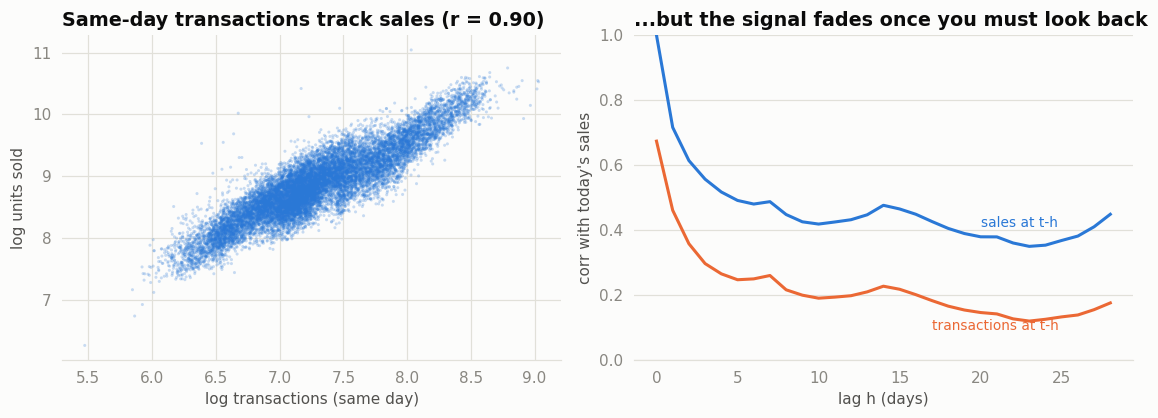

In [41]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.9))
rng = np.random.default_rng(0); ii = np.flatnonzero(both.reshape(-1)); ii = rng.choice(ii, 15000, replace=False)
axs[0].scatter(lt.reshape(-1)[ii], ls.reshape(-1)[ii], s=4, color=BLUE, alpha=.25, edgecolor="none")
axs[0].set_xlabel("log transactions (same day)"); axs[0].set_ylabel("log units sold"); axs[0].grid(True, axis="both")
axs[0].set_title(f"Same-day transactions track sales (r = {r_raw:.2f})")
axs[1].plot(lags, c_sa, color=BLUE, lw=2); axs[1].plot(lags, c_tx, color=ORANGE, lw=2)
axs[1].text(20, c_sa[20] + .03, "sales at t-h", color=BLUE, fontsize=9); axs[1].text(17, c_tx[17] - .09, "transactions at t-h", color=ORANGE, fontsize=9)
axs[1].set_xlabel("lag h (days)"); axs[1].set_ylabel("corr with today's sales"); axs[1].set_ylim(0, 1)
axs[1].set_title("...but the signal fades once you must look back")
finish(fig, "transactions")

In [42]:
last = slice(Tt - 240, Tt)
ss = pd.DataFrame({"type": st.type.values, "units_per_txn": np.nanmean(P.tot_clean[last] / P.TX[last], axis=0), "txn_per_day": np.nanmean(P.TX[last], axis=0)})
ss.groupby("type").agg(stores=("type", "size"), avg_txn_per_day=("txn_per_day", "mean"), avg_units_per_txn=("units_per_txn", "mean")).round(1)

,stores,avg_txn_per_day,avg_units_per_txn
type,,,
A,9,"3,207.70",10.40
B,8,"1,685.60",9.40
C,15,"1,003.70",8.50
D,18,"1,605.30",9.60
E,4,"1,290.20",10.60


**Business insight.** Same-day, transactions and sales move together (correlation 0.90 in logs; 0.67 after removing store and weekday averages) - **but that relationship is unusable for forecasting because same-day transactions are unknown**. What is usable is the lagged relation, and it is weak: sales(t) vs transactions(t-16) has a correlation of 0.20, *lower* than sales(t) vs its own value 16 days earlier (0.45); adding lagged transactions to a regression on lagged sales lifts R^2 only from 0.202 to 0.220, and transactions alone reach 0.04. Basket size is fairly stable (8.5-10.6 units per transaction; type A stores have ~3,200 transactions a day, type C ~1,000).
*Modeling decision:* **never use same-day transactions.** Lagged store-level transactions (windows ending at the origin) are included as *tier-3* features that must earn their place in an ablation test.

## 11b. Oil price and the economy
Ecuador is an oil-exporting economy, so oil is the classic "macro" candidate feature.

In [43]:
# --- 11b. Oil ----------------------------------------------------------------------------------------------------------------------
lf_tot = pd.Series(np.nansum(P.C[:Tt][:, lfl_stores], axis=(1, 2)), index=P.dates[:Tt]); lf_tot[np.isnan(P.C[:Tt][:, lfl_stores]).all(axis=(1, 2))] = np.nan
mo = pd.DataFrame({"sales": lf_tot.resample("MS").mean(), "oil": pd.Series(P.oil[:Tt], index=P.dates[:Tt]).resample("MS").mean()}).dropna()
mo = mo[mo.index < "2017-08-01"]
yoy = mo.pct_change(12).dropna()
print(f"monthly correlation, levels: {mo.sales.corr(mo.oil):+.2f} | year-on-year growth rates: {yoy.sales.corr(yoy.oil):+.2f}")
for k in (1, 2, 3, 6): print(f"   YoY growth of sales vs YoY oil change {k} month(s) earlier: {yoy.sales.corr(yoy.oil.shift(k)):+.2f}")
ds = np.log(lf_tot / lf_tot.shift(7)).dropna(); do = np.log(pd.Series(P.oil[:Tt], index=P.dates[:Tt]) / pd.Series(P.oil[:Tt], index=P.dates[:Tt]).shift(7)).reindex(ds.index)
m_ = ds.notna() & do.notna(); print(f"weekly log-change of sales vs oil: {np.corrcoef(ds[m_], do[m_])[0, 1]:+.2f}")
print(f"oil price at forecast origin (2017-08-15): {P.oil[Tt - 1]:.2f} | range in train {P.oil[:Tt].min():.1f}-{P.oil[:Tt].max():.1f}")

monthly correlation, levels: -0.73 | year-on-year growth rates: -0.09
   YoY growth of sales vs YoY oil change 1 month(s) earlier: -0.06
   YoY growth of sales vs YoY oil change 2 month(s) earlier: -0.10
   YoY growth of sales vs YoY oil change 3 month(s) earlier: -0.11
   YoY growth of sales vs YoY oil change 6 month(s) earlier: -0.06
weekly log-change of sales vs oil: +0.05
oil price at forecast origin (2017-08-15): 47.57 | range in train 26.2-110.6


**Business insight.** The level correlation between monthly sales and oil is -0.73, but that is a spurious trend effect (oil fell while volumes rose). Once trends are removed the relation disappears: year-on-year growth correlation -0.09, lagged 1-6 months -0.06 to -0.11, weekly log-changes +0.05. *Modeling decision:* oil (level at origin, 28-day change) is a tier-3 feature to be tested last; expect no gain for a 16-day horizon.

## 12. Seasonality by family, the test-window season and the pay-day cycle

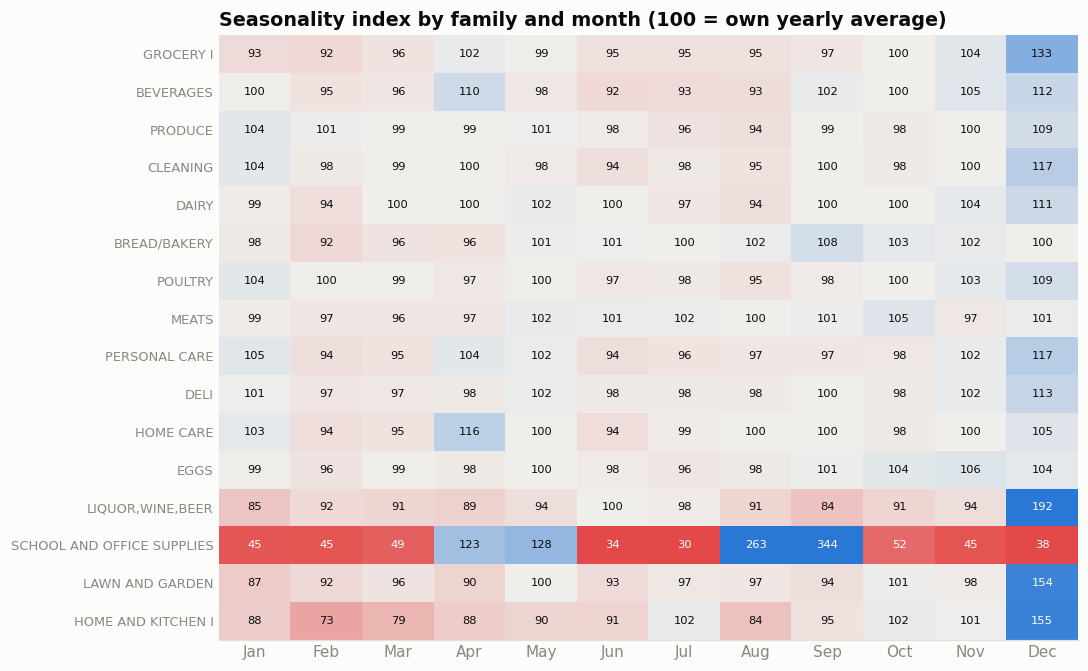

In [44]:
# --- 12. Seasonality ---------------------------------------------------------------------------------------------------
# family x month index on like-for-like stores (each family-year normalised by its own average)
famL = np.nansum(P.C[:Tt][:, lfl_stores], axis=1)                              # [T,F] LFL-store totals (NaN-aware)
famL[np.isnan(P.C[:Tt][:, lfl_stores]).all(axis=1)] = np.nan
fdf = pd.DataFrame(famL, index=P.dates[:Tt], columns=P.fams)
fdf = fdf[(fdf.index.year >= 2014) & (fdf.index.year <= 2016)]
fm = fdf.groupby([fdf.index.year, fdf.index.month]).mean()                    # year-month mean daily units
cnt = fdf.groupby([fdf.index.year, fdf.index.month]).count()
fm = fm.where(cnt >= 20)
fy = fdf.groupby(fdf.index.year).mean()
idx_fm = (fm / fy.reindex(fm.index.get_level_values(0)).values).groupby(level=1).mean().T          # family x month
show = list(fs.head(12).family) + ["LIQUOR,WINE,BEER", "SCHOOL AND OFFICE SUPPLIES", "LAWN AND GARDEN", "HOME AND KITCHEN I"]
hm = idx_fm.loc[show]
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", [fv.RED, "#f0efec", fv.BLUE])
fig, ax = plt.subplots(figsize=(10, 6.2))
im = ax.imshow(hm.values, cmap=cmap, vmin=0.4, vmax=1.6, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]); ax.set_yticks(range(len(show))); ax.set_yticklabels(show, fontsize=8.5)
ax.grid(False); ax.tick_params(length=0)
for i in range(hm.shape[0]):
    for j in range(12):
        v = hm.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v * 100:.0f}", ha="center", va="center", fontsize=7.5, color=fv.INK if 0.55 < v < 1.45 else "white")
ax.set_title("Seasonality index by family and month (100 = own yearly average)")
finish(fig, "seasonality_heatmap")

In [45]:
# the season of the test window: how does 16-31 Aug compare with the 3 weeks before it, in every past year?
lf_tot = pd.Series(np.nansum(P.C[:Tt][:, lfl_stores], axis=(1, 2)), index=P.dates[:Tt]); lf_tot[np.isnan(P.C[:Tt][:, lfl_stores]).all(axis=(1, 2))] = np.nan
famLd = pd.DataFrame(famL, index=P.dates[:Tt], columns=P.fams)
def window_ratio(series, y):
    a = series[f"{y}-08-16":f"{y}-08-31"].mean(); b = series[f"{y}-07-26":f"{y}-08-15"].mean(); return a / b - 1
rows = []
for y in (2015, 2016):                                                          # 2013-14 fall in the unreliable recording regime
    r = {"year": y, "ALL (LFL stores)": window_ratio(lf_tot, y)}
    for f in ["GROCERY I", "BEVERAGES", "PRODUCE", "SCHOOL AND OFFICE SUPPLIES", "LIQUOR,WINE,BEER", "CLEANING"]:
        r[f] = window_ratio(famLd[f], y) if famLd[f][f"{y}-07-26":f"{y}-08-31"].notna().mean() > .9 else np.nan
    rows.append(r)
sw = pd.DataFrame(rows).set_index("year")
print("change of avg daily units: 16-31 Aug vs 26 Jul-15 Aug (LFL stores)"); sw.style.format("{:+.1%}", na_rep="n/a")

change of avg daily units: 16-31 Aug vs 26 Jul-15 Aug (LFL stores)


,ALL (LFL stores),GROCERY I,BEVERAGES,PRODUCE,SCHOOL AND OFFICE SUPPLIES,"LIQUOR,WINE,BEER",CLEANING
year,,,,,,,
2015,-1.7%,-2.6%,+0.9%,-1.4%,+218.4%,-16.9%,-2.4%
2016,-1.5%,-5.8%,+0.4%,+4.7%,+311.7%,-13.1%,-3.1%


**The season of the test window (16-31 August) versus the 3 weeks before it, in past years:** overall sales are flat (-1.7% in 2015, -1.5% in 2016), but the families move very differently: **SCHOOL AND OFFICE SUPPLIES +218% (2015) and +312% (2016)** - the back-to-school peak (Ecuador's Sierra school year starts in September) - while LIQUOR falls 13-17% and GROCERY I 3-6%. This family carries only 0.16M units a year, but it will be by far the largest *relative* error in the forecast if the model does not know about it. *Modeling decisions:* year-ago features (`yoy_*`, week of year, month), a **dormant-rule exemption** for school supplies, and a validation fold that mirrors the test season (2016-08-16).

In [46]:
# payday cycle (public-sector pay days are the 15th and the last day of the month) + day-of-month profile
cal = fv.calendar_frame(P.dates[:Tt])
relp = rel_s.copy()
pay = cal.is_payday.values.astype(bool)
prof = pd.DataFrame({"dtp": cal.days_to_payday.values, "dom": cal.day_of_month.values, "month": cal.month.values})
rows = []
for name, m in [("payday (15th / last day)", pay), ("day after payday", np.roll(pay, 1)), ("2 days after payday", np.roll(pay, 2)), ("day before payday", np.roll(pay, -1)), ("all other days", ~(pay | np.roll(pay, 1) | np.roll(pay, 2) | np.roll(pay, -1)))]:
    v = relp[m]; v = v[~np.isnan(v)]; rows.append((name, np.median(v) - 1, np.mean(v) - 1, len(v)))
pd.DataFrame(rows, columns=["day type", "median_effect", "mean_effect", "store-days"]).set_index("day type").style.format({"median_effect": "{:+.1%}", "mean_effect": "{:+.1%}", "store-days": "{:,.0f}"})

,median_effect,mean_effect,store-days
day type,,,
payday (15th / last day),-0.1%,+2.1%,"5,530"
day after payday,+10.0%,+14.7%,"5,281"
2 days after payday,+6.5%,+10.6%,"5,522"
day before payday,-5.5%,-3.9%,"5,530"
all other days,-4.2%,-1.1%,"61,741"


**Pay-day cycle.** Public-sector salaries are paid on the 15th and the last day of the month. Sales are **+10% (median) the day after pay-day and +6.5% two days after**, and about -5.5% the day before; pay-day itself is neutral (-0.1%) against an average non-payday of -4.2%. The test window starts on the day after the 15 Aug pay-day (a +10% day) and ends on the 31 Aug pay-day, so this pattern is directly relevant. *Modeling decisions:* `is_payday`, `days_since_payday`, `days_to_payday`, `day_of_month`.

## 13. Store x Family volatility and intermittency
Series are classified with the Syntetos-Boylan scheme: **ADI** (average days between sales) and **CV^2** (variability of the size of sales) separate *smooth*, *erratic*, *intermittent* and *lumpy* demand - which need different forecasting treatments.

In [47]:
# --- 13. Demand volatility & intermittency at Store x Family level (Syntetos-Boylan classification) --------------------
W = P.C[Tt - 365: Tt]
nv = np.sum(~np.isnan(W), axis=0); nz = np.sum(np.nan_to_num(W) > 0, axis=0)
mean_all = np.nanmean(W, axis=0); std_all = np.nanstd(W, axis=0)
Wp = np.where(W > 0, W, np.nan); mean_nz = np.nanmean(Wp, axis=0); std_nz = np.nanstd(Wp, axis=0)
vol = pd.DataFrame({"store_nbr": np.repeat(P.stores, len(P.fams)), "family": np.tile(P.fams, len(P.stores)),
                    "valid_days": nv.reshape(-1), "sale_days": nz.reshape(-1), "mean_daily": mean_all.reshape(-1),
                    "cv_daily": (std_all / mean_all).reshape(-1), "ADI": (nv / np.maximum(nz, 1)).reshape(-1),
                    "CV2_nonzero": ((std_nz / mean_nz) ** 2).reshape(-1)})
vol = vol[(vol.valid_days >= 180) & (vol.sale_days >= 10)].copy()
vol["class"] = np.select([(vol.ADI < 1.32) & (vol.CV2_nonzero < 0.49), (vol.ADI < 1.32), (vol.CV2_nonzero < 0.49)], ["smooth", "erratic", "intermittent"], "lumpy")
vol["units"] = vol.mean_daily * vol.valid_days
cs = vol.groupby("class").agg(combos=("class", "size"), share_of_units=("units", "sum"), median_cv=("cv_daily", "median"), median_ADI=("ADI", "median"))
cs["share_of_units"] = cs.share_of_units / cs.share_of_units.sum()
print(f"combos with >=180 valid days and >=10 sale days in the last 365: {len(vol)} of {len(P.stores) * len(P.fams)}")
cs.style.format({"share_of_units": "{:.2%}", "median_cv": "{:.2f}", "median_ADI": "{:.2f}"})

combos with >=180 valid days and >=10 sale days in the last 365: 1684 of 1782


,combos,share_of_units,median_cv,median_ADI
class,,,,
erratic,290,3.16%,1.00,1.01
intermittent,177,0.01%,1.83,3.49
lumpy,87,0.02%,1.97,2.11
smooth,1130,96.81%,0.39,1.00


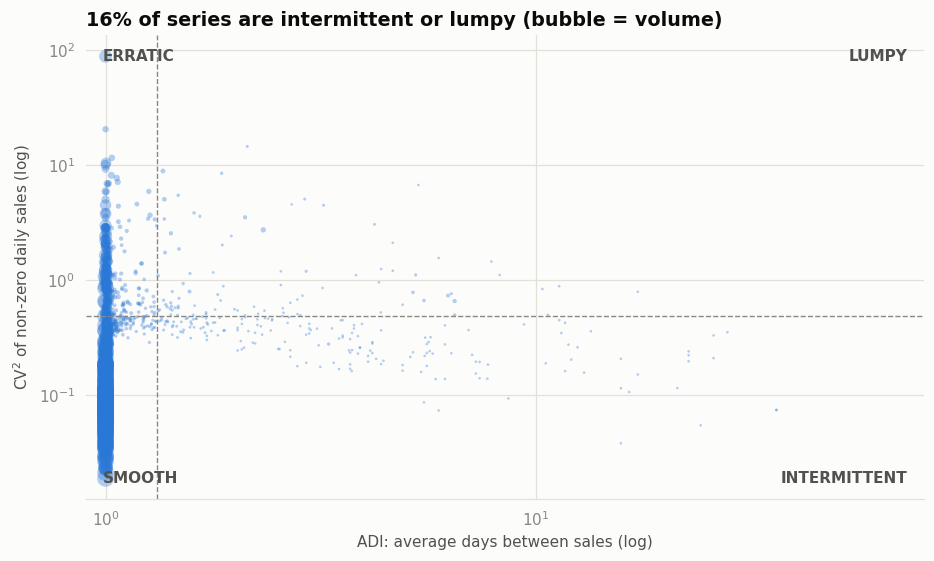

In [48]:
fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.scatter(vol.ADI, vol.CV2_nonzero, s=np.clip(np.sqrt(vol.units) / 6, 3, 120), color=BLUE, alpha=.35, edgecolor="none")
ax.axvline(1.32, color=fv.MUTED, lw=.9, ls="--"); ax.axhline(0.49, color=fv.MUTED, lw=.9, ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(True, axis="both")
ax.set_xlabel("ADI: average days between sales (log)"); ax.set_ylabel("CV$^2$ of non-zero daily sales (log)")
ax.set_xlim(0.9, 80)
for x, y, t, ha in [(0.02, 0.97, "ERRATIC", "left"), (0.98, 0.97, "LUMPY", "right"), (0.02, 0.03, "SMOOTH", "left"), (0.98, 0.03, "INTERMITTENT", "right")]:
    ax.text(x, y, t, color=fv.INK2, fontsize=10, fontweight="bold", transform=ax.transAxes, ha=ha, va="top" if y > .5 else "bottom")
share_ = (vol["class"].isin(["intermittent", "lumpy"])).mean()
ax.set_title(f"{share_:.0%} of series are intermittent or lumpy (bubble = volume)")
finish(fig, "volatility_classes")

In [49]:
vf = vol.groupby("family").agg(combos=("family", "size"), median_cv=("cv_daily", "median"), median_ADI=("ADI", "median"), units_pct=("units", "sum")).sort_values("units_pct", ascending=False)
vf["units_pct"] = vf.units_pct / vf.units_pct.sum() * 100
print("most stable families (lowest median CV) among the volume leaders:"); print(vf.head(12).round(2).to_string())
print("\nmost volatile (highest median CV, >=20 series):"); print(vf[vf.combos >= 20].nlargest(6, "median_cv").round(2).to_string())

most stable families (lowest median CV) among the volume leaders:
               combos  median_cv  median_ADI  units_pct
family                                                 
GROCERY I          53       0.29        1.00      29.67
BEVERAGES          53       0.30        1.00      22.25
PRODUCE            53       0.30        1.00      14.92
CLEANING           53       0.30        1.00       7.90
DAIRY              53       0.27        1.00       5.89
BREAD/BAKERY       53       0.27        1.00       3.50
POULTRY            53       0.31        1.00       2.51
MEATS              53       0.32        1.00       2.37
PERSONAL CARE      53       0.37        1.00       2.06
DELI               53       0.27        1.00       2.00
HOME CARE          53       0.31        1.00       1.93
EGGS               53       0.42        1.00       1.27

most volatile (highest median CV, >=20 series):
                            combos  median_cv  median_ADI  units_pct
family                          

**Business insight.** Of 1,684 series with enough history, **1,130 are "smooth" and carry 96.8% of all units**; 290 are erratic (3.2%); intermittent (177) and lumpy (87) series together carry 0.03%. The most predictable families (GROCERY I, BEVERAGES, PRODUCE, CLEANING, DAIRY, BREAD/BAKERY) have a daily coefficient of variation of only 0.27-0.31; the most volatile are SCHOOL AND OFFICE SUPPLIES (CV 2.8, one sale every 2.4 days), BABY CARE (2.7), HOME APPLIANCES (2.1), BOOKS (1.8), and FROZEN FOODS (1.4 - erratic because of the December spike). **The business risk is concentrated in a few high-volume, high-margin-of-error series - not in the many intermittent ones.**
*Modeling decisions:* volatility features (`roll_std_*`, `cv_*`, zero-rate) so that the model knows how far to trust the recent level; evaluate with RMSLE (which weights all series equally) *and* report volume-weighted error; intermittent series need no special model but must not drive the metric alone.

## 14. Anomalies, spikes, declines and inactive combinations
Detection uses a robust z-score of each day against the same weekday in the +-1-3 surrounding weeks (so weekday seasonality does not create false alarms).

In [50]:
# --- 14. Anomalies -------------------------------------------------------------------------------------------------------------
s_ = lf_tot.copy()
base = pd.concat([s_.shift(k) for k in (7, 14, 21, -7, -14, -21)], axis=1).median(axis=1)
dev = (s_ / base - 1).dropna(); mad = np.median(np.abs(dev - dev.median())) * 1.4826
an = pd.DataFrame({"units": s_.loc[dev.index], "expected": base.loc[dev.index], "deviation_%": dev * 100, "robust_z": (dev - dev.median()) / mad})
natl = raw["hol"][raw["hol"].locale == "National"].groupby("date").description.apply(lambda x: " / ".join(sorted(set(x))))
an["calendar explanation"] = [natl.get(d, "") for d in an.index]
top = an.reindex(an["robust_z"].abs().sort_values(ascending=False).index).head(14)
print(f"chain-level days with |robust z| > 4: {(an.robust_z.abs() > 4).sum()} of {len(an)}")
top.round(1)

chain-level days with |robust z| > 4: 39 of 1679


,units,expected,deviation_%,robust_z,calendar explanation
2016-04-18,"1,076,559.80","586,408.70",83.60,7.40,Terremoto Manabi+2
2014-03-04,"681,338.80","371,719.60",83.30,7.40,Carnaval
2014-01-02,"713,838.40","402,039.70",77.60,6.90,
2014-09-01,"733,955.40","424,617.20",72.90,6.50,
2015-11-03,"851,864.70","501,762.60",69.80,6.20,Independencia de Cuenca
2014-07-01,"645,308.60","383,022.10",68.50,6.10,Mundial de futbol Brasil: Octavos de Final
2013-01-02,"384,944.70","228,793.10",68.30,6.10,
2017-01-02,"1,150,478.70","685,971.50",67.70,6.00,Traslado Primer dia del ano
2017-05-01,"1,030,608.20","615,428.70",67.50,6.00,Dia del Trabajo
2014-07-02,"679,762.10","406,210.30",67.30,6.00,


In [51]:
# store x family spikes vs the series' own history (10x its 99th percentile) -> candidates for winsorising
spk = obs[(obs.p99 > 20) & (obs.x_p99 >= 10)]
print(f"observations >= 10x their own series' 99th percentile: {len(spk)} ({len(spk) / (obs.p99 > 20).sum():.4%} of rows in series with p99>20)")
print("by year:", spk.groupby(spk.date.dt.year).size().to_dict()); print("families:", spk.family.value_counts().head(6).to_dict())
print(spk.nlargest(6, "sales")[["date", "store_nbr", "family", "sales", "p99", "x_p99"]].round(1).to_string(index=False))

observations >= 10x their own series' 99th percentile: 22 (0.0010% of rows in series with p99>20)
by year: {2013: 2, 2014: 4, 2015: 5, 2016: 10, 2017: 1}
families: {'MEATS': 4, 'GROCERY II': 3, 'GROCERY I': 3, 'LINGERIE': 3, 'LIQUOR,WINE,BEER': 2, 'CELEBRATION': 2}
      date  store_nbr    family      sales      p99  x_p99
2016-05-02          2 GROCERY I 124,717.00 7,639.50  16.30
2016-10-07         39     MEATS  89,576.40 2,145.30  41.80
2014-12-08         35 GROCERY I  45,361.00 3,149.70  14.40
2015-12-14         35 GROCERY I  40,351.50 3,149.70  12.80
2015-10-03         43   POULTRY  12,143.20   384.40  31.60
2016-10-13         12     MEATS  11,609.60   264.10  44.00


In [52]:
# sustained declines: store-level 4-week average below 60% of the previous 4 weeks (Jan-Feb excluded: post-Christmas drop)
sm = pd.DataFrame(P.tot_stable[:Tt], index=P.dates[:Tt], columns=P.stores)
r28 = sm.rolling(28, min_periods=14).mean(); prev = r28.shift(28); drop = (r28 / prev)
ev = []
for s in P.stores:
    x = drop[s].dropna(); x = x[(x < 0.6) & ~x.index.month.isin([1, 2])]
    if len(x): ev.append((s, x.index[0].date(), round(x.min(), 2), len(x)))
pd.DataFrame(ev, columns=["store", "first_flagged", "worst_ratio_vs_prev_28d", "days_flagged"]).sort_values("days_flagged", ascending=False).head(8)

,store,first_flagged,worst_ratio_vs_prev_28d,days_flagged
0,2,2016-05-30,0.50,22
2,25,2016-12-07,0.48,8
1,22,2015-11-19,0.57,4


**Business insight.** 39 of 1,679 days are chain-level anomalies (|z| > 4) and almost all are **explainable by the calendar**: the Manabi earthquake (2016-04-18, +84%), Carnaval (2014-03-04, +83%), *Independencia de Cuenca*, *Dia del Trabajo*, the 2014 World Cup, and the days right after 1 January and around the start of a month (probably restocking after the closure and pay-day shopping). Store x family spikes above 10x the series' own 99th percentile are extremely rare (22 in 3 million rows, mostly MEATS / GROCERY items in 2016) - data-entry errors or bulk orders. Sustained store declines are rare too - only three stores (2, 25, 22) are flagged, for 4 to 22 days each - so there is no structural "dying store" to model; the `store_growth_*` features capture such trends if they occur.
*Modeling decisions:* no winsorising of the target (log1p handles the spikes); event and holiday flags cover the explainable anomalies; `valid_days_28d` flags stores that are recovering from a closure; the inactive-combination rule handles the dead series (section 5).

## 15. Business insights - what the numbers mean for the retailer

| # | insight | evidence | what it means operationally |
|---|---|---|---|
| 1 | **Volume is concentrated** in a few stores and families | top-10 stores = 38% of sales; 5 families = 81% of units; Quito = 52% | forecast accuracy on ~10 stores x 5 families protects most of the value; give them the most review time |
| 2 | **Weekend and pay-day rhythm** drives replenishment | Sun +30%, Sat +22%, Thu -21%; +10% the day after pay-day | order for the weekend by mid-week; a 16-day horizon always contains two full weekly cycles |
| 3 | **December and the school season** are the two big seasonal events | Dec +28%; school supplies +218-312% in the second half of August | plan stock for school supplies now - it is the largest *relative* movement in the forecast window |
| 4 | **Growth is real but slowing** | LFL +18.8% -> +7.8% -> +4.6% -> +7.3% (YTD) | do not extrapolate long trends; anchor on the recent 4-8 weeks |
| 5 | **Promotions are a weak lever** (except for liquor) | +2.3% median uplift; LIQUOR +20.7% | do not over-stock for promotions; promote alcohol if the goal is volume |
| 6 | **Discretionary lines react to holidays, staples do not** | LIQUOR +50%, electronics +37% vs MEATS +1% | holiday buying plans should target discretionary families |
| 7 | **Not every zero is lost demand** | 70% of zeros are closures, not-yet-open stores or unrecorded families | inventory KPIs (stock-outs, lost sales) must be computed from valid days only |
| 8 | **Local events matter locally** | earthquake: +31% outside the epicentre, +11% inside | keep store-level, not chain-level, event handling |

## 16. EDA summary - what the model must be told

| finding | evidence | modeling decision (Phase 3) |
|---|---|---|
| Zeros have six causes; only ~30% are demand | 939k zero rows: 24% not yet open, 41% not recorded, 4% never sold, 30% true | mask non-demand zeros (targets *and* history); dormant/never-sold -> `rule_zero`; keep true zeros |
| Chain-wide "recording regimes" and family level shifts (2013 - mid 2015) | >= 5 families vanish together in 5 windows; DAIRY/POULTRY x1.9 in Nov 2013 | mask those days; train on origins >= 2015-07-01; store totals from stable families |
| Dormant-series rule is reliable (precision 96%) but fails for school supplies in Jul-Sep | 847 flags, 18% woke up in the season of the test window | 90-day rule + seasonal exemption; `SCHOOL AND OFFICE SUPPLIES` always modeled |
| 25 Dec is absent, not zero | no rows in 4 years | keep NaN; never a target or lag |
| Strong weekly and pay-day structure | Sun +30%, Thu -21%; day after pay-day +10% | horizon-aligned same-weekday lags, weekday and pay-day features |
| Annual seasonality is family-specific | school supplies +218-312% in the test-window season; December +28% | year-ago features, month / week-of-year; a validation fold in the same season last year |
| Level shifts and slowing growth | LFL +18.8 -> +4.6% | recent-level features (7/14/28/56-day rolling means), no global trend term |
| Promotion coverage drifts (0% -> 47%), uplift is small (+2.3%), LIQUOR +21% | coverage by year; local-level uplift | relative promo features, training window >= mid-2015, family interaction via `family_id` |
| Holiday effects are local, family-specific and heterogeneous | local +/-0%, Christmas Eve +47%, Carnaval -7% | local / regional / national flags matched to store, holiday type, day before/after |
| Same-day transactions unavailable; lagged transactions weak | R^2 0.202 -> 0.220 | transactions only as lagged tier-3 features |
| Oil has no incremental signal | YoY corr -0.09 | oil as tier-3 ablation only |
| 96.8% of units are in smooth series; risk sits in a few volatile families | Syntetos-Boylan classes | volatility features; RMSLE + per-family / volume-weighted reporting |
| Rare huge spikes (22 obs > 10x p99) | anomaly scan | train on log1p(sales); clipping as a Phase-4 experiment |
| Time structure: 16-day horizon, weekly Tuesday origins | test = 16 days after a Tuesday | direct multi-horizon table, embargoed time-based validation (Phase 3, sections 1 and 9) |

**Next: Phase 3 - Feature Engineering** (`02_Feature_Engineering_Favorita.ipynb`) turns these decisions into a leakage-safe modeling table. This notebook also writes `store_family_activity_status.csv`, the status of every store x family at the forecast origin.